In [ ]:
!pip install -q ray[RLlib]

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.5/43.5 kB 1.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 965.4/965.4 kB 15.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 220.9/220.9 kB 7.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 87.2/87.2 kB 4.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 30.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.4/72.4 MB 9.8 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
langgraph-checkpoint 4.0.0 requires ormsgpack>=1.12.0, but you have ormsgpack 1.7.0 which is incompatible.


In [ ]:
!git clone https://github.com/MatthewCWeston/RLlib_TicTacToe_League

Cloning into 'RLlib_TicTacToe_League'...
remote: Enumerating objects: 124, done.
remote: Counting objects: 100% (124/124), done.
remote: Compressing objects: 100% (87/87), done.
remote: Total 124 (delta 77), reused 81 (delta 34), pack-reused 0 (from 0)
Receiving objects: 100% (124/124), 47.59 KiB | 1.76 MiB/s, done.
Resolving deltas: 100% (77/77), done.


In [ ]:
%cd RLlib_TicTacToe_League

/content/RLlib_TicTacToe_League


In [ ]:
steps_to_save =  10 # number of epochs before saving a copy in SP, FSP, PFSP, PFSP+

## Static

In [ ]:
# @title Imports
# @title Imports
import numpy as np
import functools

from ray.rllib.algorithms.ppo import PPOConfig
from ray.rllib.core.rl_module.multi_rl_module import MultiRLModuleSpec
from ray.rllib.core.rl_module.rl_module import RLModuleSpec
from ray.rllib.algorithms.ppo.torch.default_ppo_torch_rl_module import DefaultPPOTorchRLModule

from ray.rllib.examples.rl_modules.classes.action_masking_rlm import (
    ActionMaskingTorchRLModule,
)
from ray.rllib.utils.metrics import (
    TRAINING_ITERATION_TIMER,
)

from ray.rllib.utils.metrics import ENV_RUNNER_RESULTS, EVALUATION_RESULTS

import torch
from ray.rllib.core.columns import Columns

from ray.rllib.connectors.learner.add_one_ts_to_episodes_and_truncate import (
    AddOneTsToEpisodesAndTruncate,
)

import matplotlib.pyplot as plt

SHARED_CRITIC_ID = "shared_critic"
AUGMENTATION = "augmentation"
SELECTED_OPPONENT = "selected_opponent"

ACTION_MASK = "action_mask"
OBSERVATIONS = "observations"

from algo.modules.DefaultCMAPPOTorchRLModule import DefaultCMAPPOTorchRLModule
from classes.heuristics import RandHeuristicRLM, BlockWinHeuristicRLM, PerfectHeuristicRLM

2026-02-07 18:26:04,016	WARNING ppo_torch_rl_module.py:8 -- DeprecationWarning: `ray.rllib.algorithms.ppo.torch.ppo_torch_rl_module.PPOTorchRLModule` has been deprecated. Use `ray.rllib.algorithms.ppo.torch.default_ppo_torch_rl_module.DefaultPPOTorchRLModule` instead. This will raise an error in the future!


In [ ]:
# @title FixedAddOneTsToEpisodesAndTruncate
# Fixes a bug in RLLib's codebase that impacts environments with terminal rewards
from typing import Any, Dict, List, Optional

from ray.rllib.connectors.connector_v2 import ConnectorV2
from ray.rllib.core.columns import Columns
from ray.rllib.core.rl_module.rl_module import RLModule
from ray.rllib.env.multi_agent_episode import MultiAgentEpisode
from ray.rllib.utils.annotations import override
from ray.rllib.utils.postprocessing.episodes import add_one_ts_to_episodes_and_truncate
from ray.rllib.utils.typing import EpisodeType
from ray.util.annotations import PublicAPI


@PublicAPI(stability="alpha")
class FixedAddOneTsToEpisodesAndTruncate(ConnectorV2):
    """Adds an artificial timestep to all incoming episodes at the end.

    In detail: The last observations, infos, actions, and all `extra_model_outputs`
    will be duplicated and appended to each episode's data. An extra 0.0 reward
    will be appended to the episode's rewards. The episode's timestep will be
    increased by 1. Also, adds the truncated=True flag to each episode if the
    episode is not already done (terminated or truncated).

    Useful for value function bootstrapping, where it is required to compute a
    forward pass for the very last timestep within the episode,
    i.e. using the following input dict: {
      obs=[final obs],
      state=[final state output],
      prev. reward=[final reward],
      etc..
    }

    .. testcode::

        from ray.rllib.connectors.learner import AddOneTsToEpisodesAndTruncate
        from ray.rllib.env.single_agent_episode import SingleAgentEpisode
        from ray.rllib.utils.test_utils import check

        # Create 2 episodes (both to be extended by one timestep).
        episode1 = SingleAgentEpisode(
            observations=[0, 1, 2],
            actions=[0, 1],
            rewards=[0.0, 1.0],
            terminated=False,
            truncated=False,
            len_lookback_buffer=0,
        ).to_numpy()
        check(len(episode1), 2)
        check(episode1.is_truncated, False)

        episode2 = SingleAgentEpisode(
            observations=[0, 1, 2, 3, 4, 5],
            actions=[0, 1, 2, 3, 4],
            rewards=[0.0, 1.0, 2.0, 3.0, 4.0],
            terminated=True,  # a terminated episode
            truncated=False,
            len_lookback_buffer=0,
        ).to_numpy()
        check(len(episode2), 5)
        check(episode2.is_truncated, False)
        check(episode2.is_terminated, True)

        # Create an instance of this class.
        connector = AddOneTsToEpisodesAndTruncate()

        # Call the connector.
        shared_data = {}
        _ = connector(
            rl_module=None,  # Connector used here does not require RLModule.
            batch={},
            episodes=[episode1, episode2],
            shared_data=shared_data,
        )
        # Check on the episodes. Both of them should now be 1 timestep longer.
        check(len(episode1), 3)
        check(episode1.is_truncated, True)
        check(len(episode2), 6)
        check(episode2.is_truncated, False)
        check(episode2.is_terminated, True)
    """

    @override(ConnectorV2)
    def __call__(
        self,
        *,
        rl_module: RLModule,
        batch: Dict[str, Any],
        episodes: List[EpisodeType],
        explore: Optional[bool] = None,
        shared_data: Optional[dict] = None,
        **kwargs,
    ) -> Any:
        # Build the loss mask to make sure the extra added timesteps do not influence
        # the final loss and fix the terminateds and truncateds in the batch.

        # For proper v-trace execution, the rules must be as follows:
        # Legend:
        # T: terminal=True
        # R: truncated=True
        # B0: bootstrap with value 0 (also: terminal=True)
        # Bx: bootstrap with some vf-computed value (also: terminal=True)

        # batch: - - - - - - - T B0- - - - - R Bx- - - - R Bx
        # mask : t t t t t t t t f t t t t t t f t t t t t f

        # TODO (sven): Same situation as in TODO below, but for multi-agent episode.
        #  Maybe add a dedicated connector piece for this task?
        # We extend the MultiAgentEpisode's ID by a running number here to make sure
        # we treat each MAEpisode chunk as separate (for potentially upcoming v-trace
        # and LSTM zero-padding) and don't mix data from different chunks.
        if isinstance(episodes[0], MultiAgentEpisode):
            for i, ma_episode in enumerate(episodes):
                ma_episode.id_ += "_" + str(i)
                # Also change the underlying single-agent episode's
                # `multi_agent_episode_id` properties.
                for sa_episode in ma_episode.agent_episodes.values():
                    sa_episode.multi_agent_episode_id = ma_episode.id_

        for i, sa_episode in enumerate(
            self.single_agent_episode_iterator(episodes, agents_that_stepped_only=False)
        ):
            # TODO (sven): This is a little bit of a hack: By extending the Episode's
            #  ID, we make sure that each episode chunk in `episodes` is treated as a
            #  separate episode in the `self.add_n_batch_items` below. Some algos (e.g.
            #  APPO) may have >1 episode chunks from the same episode (same ID) in the
            #  training data, thus leading to a malformatted batch in case of
            #  RNN-triggered zero-padding of the train batch.
            #  For example, if e1 (id=a len=4) and e2 (id=a len=5) are two chunks of the
            #  same episode in `episodes`, the resulting batch would have an additional
            #  timestep in the middle of the episode's "row":
            #  {  "obs": {
            #    ("a", <- eps ID): [0, 1, 2, 3 <- len=4, [additional 1 ts (bad)],
            #                       0, 1, 2, 3, 4 <- len=5, [additional 1 ts]]
            #  }}
            sa_episode.id_ += "_" + str(i)

            len_ = len(sa_episode)

            # Extend all episodes by one ts.
            add_one_ts_to_episodes_and_truncate([sa_episode])

            loss_mask = [True for _ in range(len_)] + [False]
            self.add_n_batch_items(
                batch,
                Columns.LOSS_MASK,
                loss_mask,
                len_ + 1,
                sa_episode,
            )

            terminateds = [
                False for _ in range(len_)
            ] + [  # Avoid ignoring last-step rewards when lambda=0
                bool(sa_episode.is_terminated)
            ]  # Use computed value for truncated eps.  # extra timestep
            self.add_n_batch_items(
                batch,
                Columns.TERMINATEDS,
                terminateds,
                len_ + 1,
                sa_episode,
            )

        # Signal to following connector pieces that the loss-mask which masks out
        # invalid episode ts (for the extra added ts at the end) has already been
        # added to `data`.
        shared_data["_added_loss_mask_for_valid_episode_ts"] = True

        return batch

In [ ]:
# @title TicTacToe Env (Parallel)
import gymnasium as gym
from gymnasium.spaces import Box, Discrete

from ray.rllib.env.multi_agent_env import MultiAgentEnv
from ray.rllib.utils.test_utils import (
    add_rllib_example_script_args,
)

import numpy as np

#from algo.constants import ACTION_MASK, OBSERVATIONS

TTT_WIN_PATHS = np.array([
    [0,1,2],[3,4,5],[6,7,8], # Horizontal
    [0,3,6],[1,4,7],[2,5,8], # Vertical
    [0,4,8],[2,4,6]          # Diagonal
])

class TicTacToe(MultiAgentEnv):
    def __init__(self, config=None):
        super().__init__()
        self.agents = self.possible_agents = ['X','O']
        #"""
        space = gym.spaces.Dict({
            ACTION_MASK: Box(0.0, 1.0, shape=(10,)), # Action 9 is NOP
            OBSERVATIONS: Box(0.0, 1.0, (18,), np.float32)
        })
        self.observation_spaces = {
            'X': space,
            'O': space,
        }
        self.action_spaces = {
            'X': Discrete(10),
            'O': Discrete(10),
        }
        self.board = None
        self.current_player = None
    def get_obs(self):
        board = self.board.copy()
        am = np.zeros((10,))
        am[:9] += 1-board.sum(axis=0)
        am_inactive = np.zeros((10,))
        am_inactive[9] = 1
        obs = {
            'X': {
                OBSERVATIONS: board.flatten(),
                ACTION_MASK: am_inactive,
            },
            'O': {
                OBSERVATIONS: board[::-1].flatten(),
                ACTION_MASK: am_inactive,
            },
        }
        obs[self.current_player][ACTION_MASK] = am
        return obs
    def reset(self, *, seed=None, options=None):
        self.board = np.zeros((2,9), dtype=np.float32)
        self.current_player = 'X'
        return self.get_obs(), {}
    def step(self, action_dict):
        action = action_dict[self.current_player]
        rewards = {'X': 0.0, 'O': 0.0}
        terminateds = {"__all__": False}
        opponent = 'X' if self.current_player=='O' else 'O'
        # The current player will always see himself as the first row and his opponent as the second row
        board_ix = 0 if self.current_player=='X' else 1
        if (action!=9): # Env checker ignores action mask; must check this.
          self.board[board_ix][action] = 1
        board = self.board[board_ix]
        win_val = [1, 1, 1]
        for p in TTT_WIN_PATHS:
            if (board[p].sum()==3):
                rewards[self.current_player] = 1.0
                rewards[opponent] = -1.0
                # Episode is done and needs to be reset for a new game.
                terminateds["__all__"] = True
        # The board might also be full w/o any player having won/lost.
        if (self.board.sum()==9) and (terminateds["__all__"]==False):
            terminateds["__all__"] = True
        #display_board(self.board)
        self.current_player = opponent
        obs = self.get_obs()
        return (
            obs,
            rewards,
            terminateds,
            {},
            {},
        )

def display_board(board):
  board = board.reshape((2,9))
  moves = []
  for x, o in zip(board[0], board[1]):
    if (x):
      moves.append('X')
    elif (o):
      moves.append('O')
    else:
      moves.append('_')
  print(moves[:3])
  print(moves[3:6])
  print(moves[6:])
  print('-----')

def convert_board(s):
  s = s.replace('\n','')
  board = np.zeros((2,9))
  for i, c in enumerate(s):
    if (c=='X'):
      board[0][i] = 1
    elif (c=='O'):
      board[1][i] = 1
  return board



In [ ]:
# @title eval_model
def query_agent(obs_array, agent):
  obs_array = obs_array.T
  if (not isinstance(agent, torch.nn.Module)): # Heuristic, for testing
    action = agent.forward_inference({Columns.OBS: torch.tensor(obs_array.flatten()).unsqueeze(0)})['actions'][0]
    return int(action)
  obs = {}
  obs[OBSERVATIONS] = torch.tensor(obs_array).float().flatten()
  am = torch.zeros(10)
  am[:9] = torch.tensor(-obs_array.sum(axis=0)+1.).float().flatten()
  obs[ACTION_MASK] = am
  logits = agent.forward_inference({Columns.OBS: obs})['action_dist_inputs']
  action = logits.argmax() # deterministic
  return action.item()

class BoardState():
    '''
      The 'opponent' is always [1], the agent is always [0].
    '''
    def __init__(self, state, prev=None, winner=-1):
      self.state=state
      self.prev=prev
      self.winner=winner
    def check_win(self, player):
      b = self.state[:,player]
      for p in TTT_WIN_PATHS:
        if (b[p].sum()==3):
          return True
      return False
    def propose(self, opponent_model):
      next_states = []
      occupied = self.state.sum(axis=1)
      for i in range(9):
        if occupied[i]==1:
          continue
        s = self.state.copy()
        s[i][1] = 1
        if (self.check_win(1)): # Did the model lose?
          next_states.append(BoardState(s, prev=self, winner=1))
          continue
        if (s.sum() == 9):
          continue # board is full
        try:
          act = query_agent(s, opponent_model)
        except Exception as e:
          print(s)
          raise Exception()
        s[act][0] = 1
        if (self.check_win(0)): # Did the model win?
          next_states.append(BoardState(s, prev=self, winner=0))
          continue
        next_states.append(BoardState(s, prev=self))
      return next_states

def eval_model(model):
  winners = {0:[],1:[]}
  model_first = np.zeros((9,2))
  model_first[query_agent(model_first, model)][0] = 1
  opponent_first = np.zeros((9,2))
  boards_to_process = [BoardState(opponent_first), BoardState(model_first)]
  max_sum = 0
  while len(boards_to_process) > 0:
    b = boards_to_process[0]
    if (b.winner != -1):
      winners[b.winner].append(b)
    else:
      boards_to_process.extend(b.propose(model))
    del boards_to_process[0]

  for i in range(2):
    print(f'Winner: {i} count: {len(winners[i])}')
  return [len(winners[i]) for i in [0,1]]



In [ ]:
# @title Calculate win rates
from torch.distributions import Categorical

def query_agent_2(obs, agent):
    obs[OBSERVATIONS] = torch.tensor(obs[OBSERVATIONS]).float().flatten()
    am = torch.tensor(obs[ACTION_MASK]).float().flatten()
    logits = agent.forward({Columns.OBS: obs[OBSERVATIONS], ACTION_MASK: am})['action_dist_inputs']
    action = Categorical(logits.softmax(dim=0)).sample()
    return action.item()

def calc_wrs(agent_list, N=50):
  agent_list = list(filter(lambda x: '_v' in x, agent_list))
  agent_list = sorted(agent_list, key=lambda x: int(x.split('_v')[-1]))

  env = TicTacToe()

  score = 0
  # Agent, opponent, agent is X/O, win/lose/draw
  win_rates = defaultdict(lambda: defaultdict(lambda: defaultdict(lambda: defaultdict(lambda: 0))))

  for a1i in range(len(agent_list)):
    agent_name = agent_list[a1i]
    agent = algo.env_runner.module[agent_name]
    print(f"Calculating win rates for {agent_name}")
    for a2i in range(a1i, len(agent_list)):
      opponent_name = agent_list[a2i]
      opponent = algo.env_runner.module[opponent_name]
      for play_as, play_against in [('X','O'), ('O','X')]:
        agents = {
            play_as: agent,
            play_against: opponent
        }
        wr_dict = win_rates[agent_name][opponent_name][play_as]
        wr_dict_r = win_rates[opponent_name][agent_name][play_against]
        for i in range(N):
          obs, _ = env.reset()
          done = False
          rewards = defaultdict(lambda: 0)
          while (not done):
            a = {}
            for k in obs.keys():
              a[k] = query_agent_2(obs[k], agents[k])
            obs, r, term, trunc, _ = env.step(a)
            for k, r in r.items():
              rewards[k] += r
            done = term['__all__']
          wr_dict[np.sign(rewards[play_as])] += 1
          wr_dict_r[-np.sign(rewards[play_as])] += 1
  return win_rates

In [ ]:
# @title Generate visualization
fontsize = 7
cell_size = 0.14
left_label_space = 0.9
right_margin = 0.2
top_label_space = 0.6
bottom_margin = 0.2

def generate_visualization(groups, win_rates, merge, show_draws):
  # Agent, opponent, agent is X/O, win/lose/draw
  def get_color(wld):
    if (wld[1]+wld[-1]==0):
      return [1,1,1]
    if (show_draws):
      colors = np.array([[0,0,1],[1,1,1],[1,0,0]])
      wlda = np.array([wld[1], wld[0], wld[-1]],dtype=float)
      if (wlda[0]+wlda[2]>0):
        wld_cap = 0.2
        wld_m = 1. / (1.-wlda[1]/wlda.sum()*(1-wld_cap))
        wlda[1] *= wld_cap
        wlda[[0,2]] *= wld_m
      wld = wlda
    else:
      colors = np.array([[0,0,1],[1,0,0]])
      wld = np.array([wld[1], wld[-1]])
    return (wld/wld.sum()) @ colors

  def merge_data(wrab):
    tmp = wrab['X'].copy()
    for k in [-1,0,1]:
      tmp[k] += wrab['O'][k]
    return tmp

  def build_color_array(row_agents, col_agents):
      rows, cols = len(row_agents), len(col_agents)
      arr = np.zeros((rows, cols, 3), dtype=float)
      for i, a in enumerate(row_agents):
          for j, b in enumerate(col_agents):
              if (merge):
                data = merge_data(win_rates[a][b])
              else:
                data = win_rates[a][b]['X']
              arr[i, j] = get_color(data)
      return arr

  col_counts = [len(g[1]) for g in groups]
  row_counts = [len(g[1]) for g in groups]

  # figure size
  fig_w = sum(col_counts) * cell_size + left_label_space + right_margin + 0.2  # extra margin for spacing
  fig_h = sum(row_counts) * cell_size + top_label_space + bottom_margin + 0.2

  left_frac = left_label_space / fig_w
  right_frac = 1.0 - (right_margin / fig_w)
  bottom_frac = bottom_margin / fig_h
  top_frac = 1.0 - (top_label_space / fig_h)

  fig = plt.figure(figsize=(fig_w, fig_h))

  # add spacing here:
  wspace = 0.2  # horizontal space between subplot blocks
  hspace = 0.2  # vertical space between subplot blocks

  ng = len(groups)
  gs = fig.add_gridspec(
      ng, ng,
      width_ratios=col_counts,
      height_ratios=row_counts,
      left=left_frac, right=right_frac, bottom=bottom_frac, top=top_frac,
      wspace=wspace, hspace=hspace
  )

  axes = np.empty((ng, ng), dtype=object)
  for i, (row_name, row_group) in enumerate(groups):
      for j, (col_name, col_group) in enumerate(groups):
          ax = fig.add_subplot(gs[i, j])
          axes[i, j] = ax
          col_arr = build_color_array(row_group, col_group)
          if col_arr.size == 0:
              ax.axis("off")
              continue
          ax.imshow(col_arr, interpolation="nearest", aspect="equal", origin="upper")
          ax.set_xticks([])
          ax.set_yticks([])
          ax.set_frame_on(False)

  # column group names
  for j, (col_name, _) in enumerate(groups):
      pos = axes[0, j].get_position()
      x_center = pos.x0 + pos.width / 2.0
      y_top = pos.y1 + 0.01
      if (not merge):
        col_name += ' (O)'
      fig.text(x_center, y_top, col_name, ha="center", va="bottom", fontsize=fontsize)

  # row group names
  for i, (row_name, _) in enumerate(groups):
      pos = axes[i, 0].get_position()
      y_center = pos.y0 + pos.height / 2.0
      x_left = pos.x0 - 0.01
      if (not merge):
        row_name += ' (X)'
      fig.text(x_left, y_center, row_name, ha="right", va="center", fontsize=fontsize, rotation="vertical")

  plt.show()


In [ ]:
# @title Display losses
def display_losses(wcs, title):
  fig, ax = plt.subplots()
  ax.set_ylim(0, 400)
  ax.plot([x[1] for x in wcs])
  ax.set_title(title)

In [ ]:
# @title Run Training
def run_training(algo, num_iters=100, critic="main"):
  vf_losses = []
  win_counts = []

  for i in range(num_iters):
    results = algo.train()
    if ENV_RUNNER_RESULTS in results:
        mean_return = results[ENV_RUNNER_RESULTS].get(
            'module_episode_returns_mean', np.nan
        )
        vf_loss = results['learners'][critic]['vf_loss']
        vf_losses.append(vf_loss)
        mean_return = [(k, f'{v:.2f}') for k, v in mean_return.items()]
        #
        print(f"iter={i+1} VF loss={vf_loss:.2f} R={mean_return}")
    if (i%10==0):
      win_counts.append(eval_model(algo.env_runner.module['main']))
  win_counts.append(eval_model(algo.env_runner.module['main']))
  return win_counts

# SP

In [ ]:
# @title config_sp

def atm_fn(agent_id, episode, **kwargs):
    return "main"

specs = {"main": RLModuleSpec(
        module_class=ActionMaskingTorchRLModule,
        model_config={
            "head_fcnet_hiddens": (64,64),
        })}

config = (
    PPOConfig()
    .environment(TicTacToe, env_config={})
    .env_runners(
        num_env_runners=0,
        num_envs_per_env_runner=1,
    )
    .multi_agent(
          policies=['main'],
          policy_mapping_fn=atm_fn,
          # Only the learned policy should be trained.
          policies_to_train=['main'],
      )
    .training(
        lr=1e-4,
        #train_batch_size=200, # temporary
        train_batch_size=16384,
        minibatch_size=1024,
    )
    .rl_module(
        rl_module_spec=MultiRLModuleSpec(
            rl_module_specs=specs
        ),
    )
)

algo = config.build_algo()

2025-12-23 23:10:08,920	WARNING algorithm_config.py:5118 -- You are running PPO on the new API stack! This is the new default behavior for this algorithm. If you don't want to use the new API stack, set `config.api_stack(enable_rl_module_and_learner=False,enable_env_runner_and_connector_v2=False)`. For a detailed migration guide, see here: https://docs.ray.io/en/master/rllib/new-api-stack-migration-guide.html
2025-12-23 23:10:17,075	INFO worker.py:2007 -- Started a local Ray instance.
/usr/local/lib/python3.12/dist-packages/ray/_private/worker.py:2046: FutureWarning: Tip: In future versions of Ray, Ray will no longer override accelerator visible devices env var if num_gpus=0 or num_gpus=None (default). To enable this behavior and turn off this error message, set RAY_ACCEL_ENV_VAR_OVERRIDE_ON_ZERO=0
  warnings.warn(
2025-12-23 23:10:31,105	WARNING rl_module.py:459 -- DeprecationWarning: `RLModule(config=[RLModuleConfig object])` has been deprecated. Use `RLModule(observation_space=.., a

In [ ]:
win_counts_sp = run_training(algo, num_iters=100)

(pid=gcs_server) [2025-12-23 23:10:39,244 E 779 779] (gcs_server) gcs_server.cc:303: Failed to establish connection to the event+metrics exporter agent. Events and metrics will not be exported. Exporter agent status: RpcError: Running out of retries to initialize the metrics agent. rpc_code: 14
(raylet) [2025-12-23 23:10:47,087 E 882 882] (raylet) main.cc:1032: Failed to establish connection to the metrics exporter agent. Metrics will not be exported. Exporter agent status: RpcError: Running out of retries to initialize the metrics agent. rpc_code: 14
(pid=918) [2025-12-23 23:11:00,070 E 918 1041] core_worker_process.cc:842: Failed to establish connection to the metrics exporter agent. Metrics will not be exported. Exporter agent status: RpcError: Running out of retries to initialize the metrics agent. rpc_code: 14


iter=1 VF loss=0.69 R=[('main', '-0.36')]
Winner: 0 count: 788
Winner: 1 count: 105


/usr/local/lib/python3.12/dist-packages/ray/rllib/utils/metrics/stats/ema.py:124: RuntimeWarning: Mean of empty slice
  return np.nanmean(self._values_to_merge)


iter=2 VF loss=0.67 R=[('main', '-0.24')]
iter=3 VF loss=0.71 R=[('main', '-0.23')]
iter=4 VF loss=0.64 R=[('main', '-0.46')]
iter=5 VF loss=0.61 R=[('main', '-0.43')]
iter=6 VF loss=0.54 R=[('main', '-0.43')]
iter=7 VF loss=0.42 R=[('main', '-0.58')]
iter=8 VF loss=0.30 R=[('main', '-0.57')]
iter=9 VF loss=0.23 R=[('main', '-0.51')]
iter=10 VF loss=0.16 R=[('main', '-0.30')]
iter=11 VF loss=0.08 R=[('main', '-0.16')]
Winner: 0 count: 874
Winner: 1 count: 2
iter=12 VF loss=0.03 R=[('main', '-0.10')]
iter=13 VF loss=0.01 R=[('main', '-0.02')]
iter=14 VF loss=0.01 R=[('main', '-0.02')]
iter=15 VF loss=0.00 R=[('main', '-0.01')]
iter=16 VF loss=0.02 R=[('main', '0.02')]
iter=17 VF loss=0.01 R=[('main', '0.03')]
iter=18 VF loss=0.00 R=[('main', '0.00')]
iter=19 VF loss=0.00 R=[('main', '0.00')]
iter=20 VF loss=0.00 R=[('main', '-0.01')]
iter=21 VF loss=0.01 R=[('main', '0.00')]
Winner: 0 count: 806
Winner: 1 count: 12
iter=22 VF loss=0.00 R=[('main', '-0.01')]
iter=23 VF loss=0.00 R=[('mai

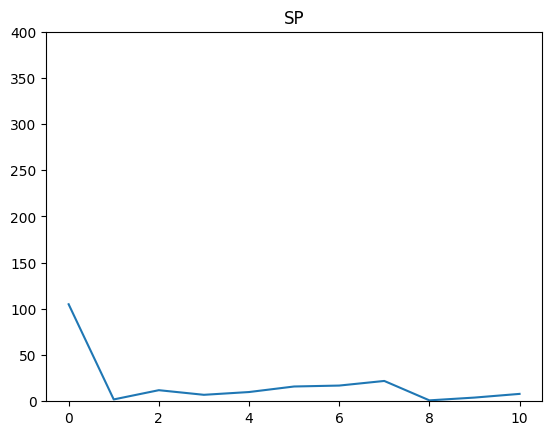

In [ ]:
display_losses(win_counts_sp, "SP")

# FSP

In [ ]:
# @title FSPCallback
from collections import defaultdict

import numpy as np

from ray.rllib.callbacks.callbacks import RLlibCallback
from ray.rllib.core.rl_module.rl_module import RLModuleSpec
from ray.rllib.core.rl_module.multi_rl_module import MultiRLModuleSpec
from ray.rllib.utils.metrics import ENV_RUNNER_RESULTS
from ray.rllib.core import (
    COMPONENT_RL_MODULE,
    COMPONENT_LEARNER,
    COMPONENT_LEARNER_GROUP,
)

def create_atm_fn(agent_names, just_added):
  ''' agent_names is a list of all league agents' names.
      wr is a dictionary of win rates '''
  def atm_fn(agent_id, episode, **kwargs):
    eid = hash(episode.id_)
    if (eid % 2 == 0) != (agent_id=='X'):
      return 'main'
    # Select an opponent.
    valid_options = list(filter(lambda s: s!='main', agent_names))
    if (len(valid_options)==0):
      return "main"
    opponent = np.random.choice(valid_options)
    return opponent
  return atm_fn

class FSPCallback(RLlibCallback):
    def __init__(self, clone_every=10):
        super().__init__()
        self.clone_every = clone_every
        self.league = ['main']
        self.win_counts = defaultdict(lambda: defaultdict(lambda:0))
        self.match_counts = defaultdict(lambda:0)
        self.version_counter = defaultdict(lambda: 1)
        # prior totals, stored on *learner*
        self.win_counts_total = defaultdict(lambda: defaultdict(lambda:0))
        self.match_counts_total = defaultdict(lambda:0)
        # Hacky fix for newly added agents not working
        self.just_added = []

    def clone_agent(self, algorithm, to_clone, reset_source=False):
      # Clone an agent
      vid = self.version_counter[to_clone]
      self.version_counter[to_clone] += 1
      new_module_id = f"{to_clone}_v{vid}"
      self.just_added.append(new_module_id)
      for opponent in self.league:
        if (opponent==to_clone):
          continue
      self.league.append(new_module_id)
      print(f"adding new opponent to the mix ({new_module_id}).")
      cloned_module = algorithm.get_module(to_clone)
      algorithm.add_module(
          module_id=new_module_id,
          module_spec=RLModuleSpec.from_module(cloned_module),
      )
      module_updates = {new_module_id: cloned_module.get_state(),}
      # Syncs weights across everything
      algorithm.set_state(
          {
              COMPONENT_LEARNER_GROUP: {
                  COMPONENT_LEARNER: {
                      COMPONENT_RL_MODULE: module_updates
                  }
              },
          }
      )

    def update_atm_fn(self, algorithm):
        # Set new mapping function
        agent_to_module_mapping_fn = create_atm_fn(self.league, self.just_added)
        algorithm.config._is_frozen = False
        algorithm.config.multi_agent(policy_mapping_fn=agent_to_module_mapping_fn)
        algorithm.config.freeze()
        # Add to (training) EnvRunners.
        def _add(_env_runner, _module_spec=None):
            _env_runner.config.multi_agent(
                policy_mapping_fn=agent_to_module_mapping_fn,
            )
            return MultiRLModuleSpec.from_module(_env_runner.module)
        algorithm.env_runner_group.foreach_env_runner(_add)

    def on_train_result(self, *, algorithm, metrics_logger=None, result, **kwargs):
        #
        self.just_added = []
        iter = algorithm.iteration
        print(f"Iter={iter}:")
        if (iter)%self.clone_every==0:
          self.clone_agent(algorithm, 'main')
        # Update mapping function, reweighting and adding new module if needed
        self.update_atm_fn(algorithm)

    @override(RLlibCallback)
    def on_sample_end(
        self,
        *,
        env_runner = None,
        metrics_logger = None,
        samples,
        # TODO (sven): Deprecate these args.
        worker = None,
        **kwargs,
    ) -> None:
        if (not env_runner.config.in_evaluation):
          if (samples[0].env_t_started > 0):
            del samples[0] # might be a continuation
          if (not samples[-1].is_done):
            del samples[-1]


In [ ]:
# @title config_fsp

def atm_fn(agent_id, episode, **kwargs):
    return "main"

sp_callback = functools.partial(FSPCallback,
                                clone_every=steps_to_save)

specs = {"main": RLModuleSpec(
        module_class=ActionMaskingTorchRLModule,
        model_config={
            "head_fcnet_hiddens": (64,64),
        })}

config = (
    PPOConfig()
    .environment(TicTacToe, env_config={})
    .callbacks( # set up our league
        sp_callback
    )
    .env_runners(
        num_env_runners=0,
        num_envs_per_env_runner=1,
    )
    .multi_agent(
          policies=['main'],
          policy_mapping_fn=atm_fn,
          # Only the learned policy should be trained.
          policies_to_train=['main'],
      )
    .training(
        lr=1e-4,
        #train_batch_size=200, # temporary
        train_batch_size=16384,
        minibatch_size=1024,
    )
    .rl_module(
        rl_module_spec=MultiRLModuleSpec(
            rl_module_specs=specs
        ),
    )
)

algo = config.build_algo()

/usr/local/lib/python3.12/dist-packages/gymnasium/envs/registration.py:644: UserWarning: WARN: Overriding environment rllib-multi-agent-env-v0 already in registry.
  logger.warn(f"Overriding environment {new_spec.id} already in registry.")
2025-12-24 04:47:32,600	WARNING util.py:61 -- Install gputil for GPU system monitoring.


In [ ]:
win_counts_fsp = run_training(algo, num_iters=100)

Iter=1:
iter=1 VF loss=0.71 R=[('main', '-0.33')]
Winner: 0 count: 677
Winner: 1 count: 143
Iter=2:
iter=2 VF loss=0.72 R=[('main', '-0.40')]
Iter=3:
iter=3 VF loss=0.73 R=[('main', '-0.39')]
Iter=4:
iter=4 VF loss=0.70 R=[('main', '-0.22')]
Iter=5:
iter=5 VF loss=0.64 R=[('main', '-0.39')]
Iter=6:
iter=6 VF loss=0.53 R=[('main', '-0.49')]
Iter=7:
iter=7 VF loss=0.41 R=[('main', '-0.49')]
Iter=8:
iter=8 VF loss=0.31 R=[('main', '-0.56')]
Iter=9:
iter=9 VF loss=0.23 R=[('main', '-0.53')]
Iter=10:
adding new opponent to the mix (main_v1).
iter=10 VF loss=0.16 R=[('main', '-0.41')]
Iter=11:
iter=11 VF loss=0.09 R=[('main', '0.99'), (np.str_('main_v1'), '-0.99')]
Winner: 0 count: 852
Winner: 1 count: 0
Iter=12:
iter=12 VF loss=0.10 R=[('main', '0.00'), (np.str_('main_v1'), '0.00')]
Iter=13:
iter=13 VF loss=0.08 R=[('main', '0.00'), (np.str_('main_v1'), '0.00')]
Iter=14:
iter=14 VF loss=0.06 R=[('main', '0.14'), (np.str_('main_v1'), '-0.14')]
Iter=15:
iter=15 VF loss=0.07 R=[('main', '0.13'

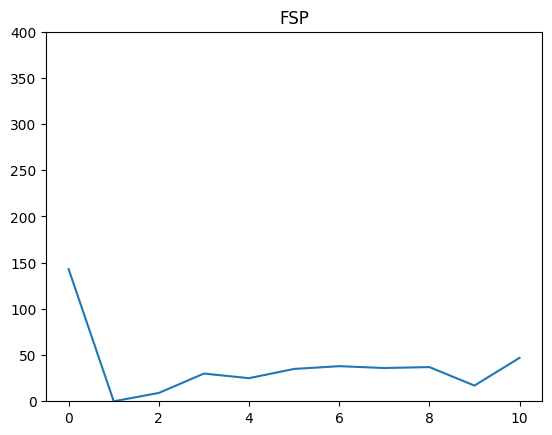

In [ ]:
display_losses(win_counts_fsp, "FSP")

In [ ]:
# @title WR calculations
learned_agent = algo.env_runner.module['main']
agent_list = algo.config.policies

win_rates = calc_wrs(agent_list)

Calculating win rates for main_v1
Calculating win rates for main_v2
Calculating win rates for main_v3
Calculating win rates for main_v4
Calculating win rates for main_v5
Calculating win rates for main_v6
Calculating win rates for main_v7
Calculating win rates for main_v8
Calculating win rates for main_v9
Calculating win rates for main_v10


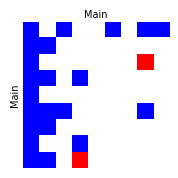

In [ ]:
# @title vis
main_agents = list(filter(lambda x: 'main_v' in x, agent_list))
groups = [
    ("Main", main_agents[:-1]),
]

merge = True # @param {"type":"boolean"}
show_draws = False # @param {"type":"boolean"}
generate_visualization(groups, win_rates, merge, show_draws)

# PFSP

In [ ]:
# @title PFSPCallback
from collections import defaultdict

import numpy as np

from ray.rllib.callbacks.callbacks import RLlibCallback
from ray.rllib.core.rl_module.rl_module import RLModuleSpec
from ray.rllib.core.rl_module.multi_rl_module import MultiRLModuleSpec
from ray.rllib.utils.metrics import ENV_RUNNER_RESULTS
from ray.rllib.core import (
    COMPONENT_RL_MODULE,
    COMPONENT_LEARNER,
    COMPONENT_LEARNER_GROUP,
)

def pfsp(agent, opponents, wr, rng):
  weights = np.array([wr[o][agent] for o in opponents])
  weights = weights**2
  wr_sum = weights.sum()
  if (wr_sum == 0):
    return rng.choice(opponents)
  return rng.choice(opponents, p=weights/wr_sum)

def create_atm_fn(agent_names, wr, just_added):
  ''' agent_names is a list of all league agents' names.
      wr is a dictionary of win rates '''
  def atm_fn(agent_id, episode, **kwargs):
    eid = hash(episode.id_)
    rng = np.random.default_rng(seed=abs(eid))
    if (eid % 2 == 0) != (agent_id=='X'):
      return 'main'
    # Select an opponent.
    valid_options = list(filter(lambda s: s!='main', agent_names))
    if (len(valid_options)==0):
      return "main"
    return pfsp("main", valid_options, wr, rng)
  return atm_fn

def get_mc_string(agent1, agent2):
  return '-'.join(sorted([agent1, agent2]))

class PFSPCallback(RLlibCallback):
    def __init__(self, clone_every=10):
        super().__init__()
        self.clone_every = clone_every
        self.league = ['main']
        self.win_counts = defaultdict(lambda: defaultdict(lambda:0))
        self.match_counts = defaultdict(lambda:0)
        self.version_counter = defaultdict(lambda: 1)
        # Track previous totals to facilitate stat inheriting
        self.win_counts_t = defaultdict(lambda: defaultdict(lambda:0))
        self.match_counts_t = defaultdict(lambda:0)
        # Hacky fix for newly added agents not working
        self.just_added = []

    def on_episode_end(
        self,
        *,
        episode,
        env_runner,
        metrics_logger,
        env,
        env_index,
        rl_module,
        **kwargs,
    ) -> None:
        x_agent = episode.module_for('X')
        o_agent = episode.module_for('O')
        # Avoid errors due to "complete_episodes" not being enabled
        rewards = episode.get_rewards()
        if ('X' not in rewards or 'O' not in rewards):
          return
        # Update stats
        outcome = np.sign(rewards['X'][-1])
        self.match_counts[get_mc_string(x_agent, o_agent)] += 1
        metrics_logger.log_value(
            f"match_count_{get_mc_string(x_agent,o_agent)}",
            1.0,
            reduce='lifetime_sum'
        )
        if (x_agent==o_agent and outcome != 0):
          metrics_logger.log_value(
              f"win_count_{x_agent}{o_agent}",
              0.5,
              reduce='lifetime_sum'
          )
        elif (outcome == 1):
          metrics_logger.log_value(
              f"win_count_{x_agent}{o_agent}",
              1.0,
              reduce='lifetime_sum'
          )
        elif (outcome == -1):
          metrics_logger.log_value(
              f"win_count_{o_agent}{x_agent}",
              1.0,
              reduce='lifetime_sum'
          )

    def inherit_stats(self, new_module_id):
        ''' Called on the envrunners; populates their stats for new agents. '''
        to_clone = new_module_id.split('_v')[0]
        # Inherit current agent's win statistics
        for opponent in list(self.win_counts[to_clone].keys()):
          if ('_v' not in opponent): # No reason to track b/t frozen agents
            self.win_counts[new_module_id][opponent] = self.win_counts[to_clone][opponent]
            self.win_counts[opponent][new_module_id] = self.win_counts[opponent][to_clone]
            self.match_counts[get_mc_string(new_module_id, opponent)] = self.match_counts[get_mc_string(to_clone, opponent)]

    def clone_agent(self, algorithm, to_clone):
      # Clone an agent
      vid = self.version_counter[to_clone]
      self.version_counter[to_clone] += 1
      new_module_id = f"{to_clone}_v{vid}"
      self.just_added.append(new_module_id)
      for opponent in self.league:
        if (opponent==to_clone):
          continue
      self.league.append(new_module_id)
      print(f"adding new opponent to the mix ({new_module_id}).")
      # Everything only faces main, so inheriting stats isn't helpful.
      for opponent in list(self.win_counts[to_clone].keys()):
        # Reduce after cloning, to provide a 'fresh start'
        self.match_counts[get_mc_string(to_clone, opponent)] /= 10
        self.win_counts[to_clone][opponent] /= 10
        if (to_clone != opponent):
          self.win_counts[opponent][to_clone] /= 10
      #self.inherit_stats(new_module_id)
      cloned_module = algorithm.get_module(to_clone)
      algorithm.add_module(
          module_id=new_module_id,
          module_spec=RLModuleSpec.from_module(cloned_module),
      )
      module_updates = {new_module_id: cloned_module.get_state(),}
      # Syncs weights across everything
      algorithm.set_state(
          {
              COMPONENT_LEARNER_GROUP: {
                  COMPONENT_LEARNER: {
                      COMPONENT_RL_MODULE: module_updates
                  }
              },
          }
      )

    def build_stats_from_results(self, result):
        league_size = len(self.league)
        wrs = defaultdict(lambda:defaultdict(lambda:0))
        new_matches = {} # Just for debugging / observation
        for i in range(league_size-1):
          a = self.league[i]
          for j in range(i, league_size):
            b = self.league[j]
            # Record statistics involving a learning agent
            if (('_v' not in a) or ('_v' not in b)):
              k = get_mc_string(a,b)
              mc_total = result.get(f"match_count_{k}", 0)
              wcab_total = result.get(f"win_count_{a}{b}", 0)
              wcba_total = result.get(f"win_count_{b}{a}", 0)
              new_matches[k] = mc_total - self.match_counts_t[k]
              # Update match count tracker
              self.match_counts[k] += new_matches[k]
              self.match_counts_t[k] = mc_total # tracks previous result stat
              # Update win count tracker
              self.win_counts[a][b] += wcab_total - self.win_counts_t[a][b]
              self.win_counts_t[a][b] = wcab_total
              if (a!=b): # Don't double-count wins for self-play
                self.win_counts[b][a] += wcba_total - self.win_counts_t[b][a]
                self.win_counts_t[b][a] = wcba_total
              if (self.match_counts[k] != 0):
                # The actual rate of wins
                # Useful for prioritizing threatening opponents, when using p=wr(b,a) rather than p=wr(a,b)*wr(b,a)
                wrs[a][b] = self.win_counts[a][b] / self.match_counts[k]
                wrs[b][a] = self.win_counts[b][a] / self.match_counts[k]
              else:
                wrs[a][b] = 1/3
                wrs[b][a] = 1/3 # Initialize as 33/33/33
        return wrs, new_matches

    def update_atm_fn(self, algorithm, wr):
        # Set new mapping function
        agent_to_module_mapping_fn = create_atm_fn(self.league, wr, self.just_added)
        algorithm.config._is_frozen = False
        algorithm.config.multi_agent(policy_mapping_fn=agent_to_module_mapping_fn)
        algorithm.config.freeze()
        # Add to (training) EnvRunners.
        def _add(_env_runner, _module_spec=None):
            _env_runner.config.multi_agent(
                policy_mapping_fn=agent_to_module_mapping_fn,
            )
            return MultiRLModuleSpec.from_module(_env_runner.module)
        algorithm.env_runner_group.foreach_env_runner(_add)

    def on_train_result(self, *, algorithm, metrics_logger=None, result, **kwargs):
        # Rebuild a set of stats with information from our env runners
        wrs, nm = self.build_stats_from_results(result[ENV_RUNNER_RESULTS])
        #
        self.just_added = []
        iter = algorithm.iteration
        print(f"Iter={iter}:")
        print(f"Matchups: {dict(self.match_counts_t)}")
        print(f"Matchups (for probabilities): {dict(self.match_counts)}")
        print(f"Win rates (main):")
        for o, wr in wrs['main'].items():
          new_matches = nm[get_mc_string('main',o)]
          if (new_matches!=0):
            wr_inv = wrs[o]['main']
            dw = 1 - wr - wr_inv
            print(f'\t\t{o}: {wr:.02f}-{dw:.02f}-{wr_inv:.02f} (+{new_matches})')
        if (iter)%self.clone_every==0:
          self.clone_agent(algorithm, "main")
        # Update mapping function, reweighting and adding new module if needed
        self.update_atm_fn(algorithm, wrs)

    @override(RLlibCallback)
    def on_sample_end(
        self,
        *,
        env_runner = None,
        metrics_logger = None,
        samples,
        # TODO (sven): Deprecate these args.
        worker = None,
        **kwargs,
    ) -> None:
        if (not env_runner.config.in_evaluation):
          if (samples[0].env_t_started > 0):
            del samples[0] # might be a continuation
          if (not samples[-1].is_done):
            del samples[-1]


In [ ]:
# @title config_pfsp
steps_to_save = 10
def atm_fn(agent_id, episode, **kwargs):
    return "main"

sp_callback = functools.partial(PFSPCallback,
                                clone_every=steps_to_save)

specs = {"main": RLModuleSpec(
        module_class=ActionMaskingTorchRLModule,
        model_config={
            "head_fcnet_hiddens": (64,64),
        })}

config = (
    PPOConfig()
    .environment(TicTacToe, env_config={})
    .callbacks( # set up our league
        sp_callback
    )
    .env_runners(
        num_env_runners=0,
        num_envs_per_env_runner=1,
    )
    .multi_agent(
          policies=['main'],
          policy_mapping_fn=atm_fn,
          # Only the learned policy should be trained.
          policies_to_train=['main'],
      )
    .training(
        lr=1e-4,
        #train_batch_size=200, # temporary
        train_batch_size=16384,
        minibatch_size=1024,
    )
    .rl_module(
        rl_module_spec=MultiRLModuleSpec(
            rl_module_specs=specs
        ),
    )
)

algo = config.build_algo()

2025-12-25 08:31:16,559	WARNING algorithm_config.py:5118 -- You are running PPO on the new API stack! This is the new default behavior for this algorithm. If you don't want to use the new API stack, set `config.api_stack(enable_rl_module_and_learner=False,enable_env_runner_and_connector_v2=False)`. For a detailed migration guide, see here: https://docs.ray.io/en/master/rllib/new-api-stack-migration-guide.html
2025-12-25 08:31:24,186	INFO worker.py:2007 -- Started a local Ray instance.
/usr/local/lib/python3.12/dist-packages/ray/_private/worker.py:2046: FutureWarning: Tip: In future versions of Ray, Ray will no longer override accelerator visible devices env var if num_gpus=0 or num_gpus=None (default). To enable this behavior and turn off this error message, set RAY_ACCEL_ENV_VAR_OVERRIDE_ON_ZERO=0
  warnings.warn(
2025-12-25 08:31:37,015	WARNING rl_module.py:459 -- DeprecationWarning: `RLModule(config=[RLModuleConfig object])` has been deprecated. Use `RLModule(observation_space=.., a

In [ ]:
win_counts_pfsp = run_training(algo, num_iters=100)

(raylet) [2025-12-25 08:31:54,181 E 2270 2270] (raylet) main.cc:1032: Failed to establish connection to the metrics exporter agent. Metrics will not be exported. Exporter agent status: RpcError: Running out of retries to initialize the metrics agent. rpc_code: 14
(pid=2307) [2025-12-25 08:32:05,140 E 2307 2407] core_worker_process.cc:842: Failed to establish connection to the metrics exporter agent. Metrics will not be exported. Exporter agent status: RpcError: Running out of retries to initialize the metrics agent. rpc_code: 14


Iter=1:
Matchups: {}
Matchups (for probabilities): {}
Win rates (main):
iter=1 VF loss=0.69 R=[('main', '-0.22')]
Winner: 0 count: 827
Winner: 1 count: 81


/usr/local/lib/python3.12/dist-packages/ray/rllib/utils/metrics/stats/ema.py:124: RuntimeWarning: Mean of empty slice
  return np.nanmean(self._values_to_merge)


Iter=2:
Matchups: {}
Matchups (for probabilities): {}
Win rates (main):
iter=2 VF loss=0.69 R=[('main', '-0.29')]
Iter=3:
Matchups: {}
Matchups (for probabilities): {}
Win rates (main):
iter=3 VF loss=0.70 R=[('main', '-0.17')]
Iter=4:
Matchups: {}
Matchups (for probabilities): {}
Win rates (main):
iter=4 VF loss=0.63 R=[('main', '-0.29')]
Iter=5:
Matchups: {}
Matchups (for probabilities): {}
Win rates (main):
iter=5 VF loss=0.55 R=[('main', '-0.42')]
Iter=6:
Matchups: {}
Matchups (for probabilities): {}
Win rates (main):
iter=6 VF loss=0.52 R=[('main', '-0.59')]
Iter=7:
Matchups: {}
Matchups (for probabilities): {}
Win rates (main):
iter=7 VF loss=0.39 R=[('main', '-0.57')]
Iter=8:
Matchups: {}
Matchups (for probabilities): {}
Win rates (main):
iter=8 VF loss=0.29 R=[('main', '-0.42')]
Iter=9:
Matchups: {}
Matchups (for probabilities): {}
Win rates (main):
iter=9 VF loss=0.18 R=[('main', '-0.35')]
Iter=10:
Matchups: {}
Matchups (for probabilities): {}
Win rates (main):
adding new oppo

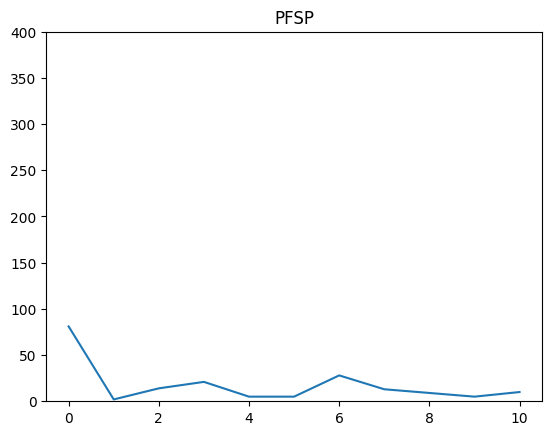

In [ ]:
display_losses(win_counts_pfsp, "PFSP")

In [ ]:
# @title WR calculations
learned_agent = algo.env_runner.module['main']
agent_list = algo.config.policies

win_rates = calc_wrs(agent_list)

Calculating win rates for main_v1
Calculating win rates for main_v2
Calculating win rates for main_v3
Calculating win rates for main_v4
Calculating win rates for main_v5
Calculating win rates for main_v6
Calculating win rates for main_v7
Calculating win rates for main_v8
Calculating win rates for main_v9
Calculating win rates for main_v10


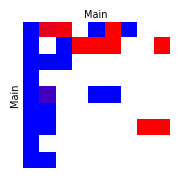

In [ ]:
# @title vis
merge = True # @param {"type":"boolean"}
show_draws = False # @param {"type":"boolean"}

main_agents = list(filter(lambda x: 'main_v' in x, agent_list))[:-1]
groups = [
    ("Main", main_agents),
]

generate_visualization(groups, win_rates, merge, show_draws)

With squared PFSP weights
```

```

With linear PFSP weights
```
Search "Winner: 1 count: " (11 hits in 1 file of 1 searched) [Extended]
  new 1 (11 hits)
	Line   9: Winner: 1 count: 86
	Line  56: Winner: 1 count: 4
	Line 109: Winner: 1 count: 6
	Line 172: Winner: 1 count: 17
	Line 245: Winner: 1 count: 29
	Line 328: Winner: 1 count: 42
	Line 421: Winner: 1 count: 28
	Line 524: Winner: 1 count: 26
	Line 637: Winner: 1 count: 15
	Line 760: Winner: 1 count: 26
	Line 880: Winner: 1 count: 23
```

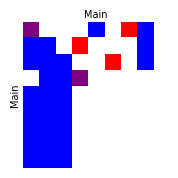

# Experimental Self Play

In [ ]:
# @title CloningCallback
from collections import defaultdict

import numpy as np

from ray.rllib.callbacks.callbacks import RLlibCallback
from ray.rllib.core.rl_module.rl_module import RLModuleSpec
from ray.rllib.core.rl_module.multi_rl_module import MultiRLModuleSpec
from ray.rllib.utils.metrics import ENV_RUNNER_RESULTS
from ray.rllib.core import (
    COMPONENT_RL_MODULE,
    COMPONENT_LEARNER,
    COMPONENT_LEARNER_GROUP,
)

class CloningCallback(RLlibCallback):
    def __init__(self, name_to_mid, clone_every=10):
        super().__init__()
        self.clone_every = clone_every
        self.league = ['main']
        self.win_counts = defaultdict(lambda: defaultdict(lambda:0))
        self.match_counts = defaultdict(lambda:0)
        self.version_counter = defaultdict(lambda: 1)
        # prior totals, stored on *learner*
        self.win_counts_total = defaultdict(lambda: defaultdict(lambda:0))
        self.match_counts_total = defaultdict(lambda:0)
        self.name_to_mid=name_to_mid
        # Hacky fix for newly added agents not working
        self.just_added = []

    def clone_agent(self, algorithm, to_clone, reset_source=False):
      # Clone an agent
      vid = self.version_counter[to_clone]
      self.version_counter[to_clone] += 1
      new_module_id = f"{to_clone}_v{vid}"
      self.just_added.append(new_module_id)
      for opponent in self.league:
        if (opponent==to_clone):
          continue
      self.league.append(new_module_id)
      print(f"adding new opponent to the mix ({new_module_id}).")
      cloned_module = algorithm.get_module(to_clone)
      algorithm.add_module(
          module_id=new_module_id,
          module_spec=RLModuleSpec.from_module(cloned_module),
      )
      module_updates = {new_module_id: cloned_module.get_state(),}
      # update shared critic, syncing weights (get_module only looks at envrunners, can't use)
      sc = algorithm.learner_group._learner._module[SHARED_CRITIC_ID]
      sc.new_agent_embedding(
          # Copy embedding of most recent clone, since self-play stops after 1st
          self.name_to_mid(new_module_id)-1,
          self.name_to_mid(new_module_id),
      )
      # Share out updated shared critic to learners
      module_updates[SHARED_CRITIC_ID] = sc.get_state()
      # Syncs weights across everything
      algorithm.set_state(
          {
              COMPONENT_LEARNER_GROUP: {
                  COMPONENT_LEARNER: {
                      COMPONENT_RL_MODULE: module_updates
                  }
              },
          }
      )
      return new_module_id

    def on_train_result(self, *, algorithm, metrics_logger=None, result, **kwargs):
        #
        self.just_added = []
        iter = algorithm.iteration
        print(f"Iter={iter}:")
        if (iter)%self.clone_every==0:
          self.just_added.append(self.clone_agent(algorithm, 'main'))
        # Workaround for a bug in RLlib. Newly created modules behave strangely for the first epoch; I think the weights are off.
        algorithm.env_runner_group.foreach_env_runner(
            lambda worker: worker.module.hold_out_modules(self.just_added)
        )

## CMAPPO

In [ ]:
# @title CMAPPOLearner (Just points to CounterfactualAdvantageEstimation)
import abc
from typing import Any, Dict

from ray.rllib.algorithms.ppo.ppo import (
    LEARNER_RESULTS_CURR_ENTROPY_COEFF_KEY,
    LEARNER_RESULTS_KL_KEY,
    PPOConfig,
)
from ray.rllib.connectors.learner import (
    AddOneTsToEpisodesAndTruncate,
    GeneralAdvantageEstimation,
)
from ray.rllib.core.learner.learner import Learner
from ray.rllib.core.rl_module.apis.value_function_api import ValueFunctionAPI
from ray.rllib.utils.annotations import (
    override,
    OverrideToImplementCustomLogic_CallToSuperRecommended,
)
from ray.rllib.utils.lambda_defaultdict import LambdaDefaultDict
from ray.rllib.utils.metrics import (
    NUM_ENV_STEPS_SAMPLED_LIFETIME,
    NUM_MODULE_STEPS_TRAINED,
)
from ray.rllib.utils.numpy import convert_to_numpy
from ray.rllib.utils.schedules.scheduler import Scheduler
from ray.rllib.utils.typing import ModuleID, TensorType

class CMAPPOLearner(Learner):

    # Deal with GAE somehow. Maybe skip it and move the logic over here, into the value loss calculation method. Saves us a VF pass, too.
    @override(Learner)
    def build(self) -> None:
        super().build() # We call Learner's build function, not PPOLearner's
        learner_config_dict = self.config.learner_config_dict

        # Dict mapping module IDs to the respective entropy Scheduler instance.
        self.entropy_coeff_schedulers_per_module: Dict[
            ModuleID, Scheduler
        ] = LambdaDefaultDict(
            lambda module_id: Scheduler(
                fixed_value_or_schedule=(
                    self.config.get_config_for_module(module_id).entropy_coeff
                ),
                framework=self.framework,
                device=self._device,
            )
        )

        # Set up KL coefficient variables (per module).
        # Note that the KL coeff is not controlled by a Scheduler, but seeks
        # to stay close to a given kl_target value.
        self.curr_kl_coeffs_per_module: Dict[ModuleID, TensorType] = LambdaDefaultDict(
            lambda module_id: self._get_tensor_variable(
                self.config.get_config_for_module(module_id).kl_coeff
            )
        )

        # Extend all episodes by one artificial timestep to allow the value function net
        # to compute the bootstrap values (and add a mask to the batch to know, which
        # slots to mask out).
        if (
            self._learner_connector is not None
            and self.config.add_default_connectors_to_learner_pipeline
        ):
            # Before anything, add one ts to each episode (and record this in the loss
            # mask, so that the computations at this extra ts are not used to compute
            # the loss).
            self._learner_connector.prepend(FixedAddOneTsToEpisodesAndTruncate())
            # At the end of the pipeline (when the batch is already completed), add the
            # GAE connector, which performs a vf forward pass, then computes the GAE
            # computations, and puts the results of this (advantages, value targets)
            # directly back in the batch. This is then the batch used for
            # `forward_train` and `compute_losses`.
            self._learner_connector.append(
                MultiOpponentAdvantageEstimation(
                    gamma=self.config.gamma,
                    lambda_=self.config.lambda_,
                    name_to_module_index=learner_config_dict['name_to_module_index'],
                )
            )

    @override(Learner)
    def remove_module(self, module_id: ModuleID, **kwargs):
        marl_spec = super().remove_module(module_id, **kwargs)
        if (module_id != SHARED_CRITIC_ID):
          self.entropy_coeff_schedulers_per_module.pop(module_id, None)
          self.curr_kl_coeffs_per_module.pop(module_id, None)
        return marl_spec

    @OverrideToImplementCustomLogic_CallToSuperRecommended
    @override(Learner)
    def after_gradient_based_update(
        self,
        *,
        timesteps: Dict[str, Any],
    ) -> None:
        super().after_gradient_based_update(timesteps=timesteps)

        for module_id, module in self.module._rl_modules.items():
            if (module_id == SHARED_CRITIC_ID):
              continue # Policy terms irrelevant to shared critic.
            config = self.config.get_config_for_module(module_id)
            # Update entropy coefficient via our Scheduler.
            new_entropy_coeff = self.entropy_coeff_schedulers_per_module[
                module_id
            ].update(timestep=timesteps.get(NUM_ENV_STEPS_SAMPLED_LIFETIME, 0))
            self.metrics.log_value(
                (module_id, LEARNER_RESULTS_CURR_ENTROPY_COEFF_KEY),
                new_entropy_coeff,
                window=1,
            )
            if (
                config.use_kl_loss
                and self.metrics.peek((module_id, NUM_MODULE_STEPS_TRAINED), default=0)
                > 0
                and (module_id, LEARNER_RESULTS_KL_KEY) in self.metrics
            ):
                kl_loss = convert_to_numpy(
                    self.metrics.peek((module_id, LEARNER_RESULTS_KL_KEY))
                )
                self._update_module_kl_coeff(
                    module_id=module_id,
                    config=config,
                    kl_loss=kl_loss,
                )

    @classmethod
    @override(Learner)
    def rl_module_required_apis(cls) -> list[type]:
        # We no longer require value functions for modules, since there's a central critic
        return []

    @abc.abstractmethod
    def _update_module_kl_coeff(
        self,
        *,
        module_id: ModuleID,
        config: PPOConfig,
        kl_loss: float,
    ) -> None:
        """Dynamically update the KL loss coefficients of each module.

        The update is completed using the mean KL divergence between the action
        distributions current policy and old policy of each module. That action
        distribution is computed during the most recent update/call to `compute_loss`.

        Args:
            module_id: The module whose KL loss coefficient to update.
            config: The AlgorithmConfig specific to the given `module_id`.
            kl_loss: The mean KL loss of the module, computed inside
                `compute_loss_for_module()`.
        """

In [ ]:
# @title CMAPPOConfig
import logging
from typing import Any, Dict, List, Optional, Type, Union, TYPE_CHECKING

from ray.rllib.algorithms.algorithm import Algorithm
from ray.rllib.algorithms.algorithm_config import AlgorithmConfig, NotProvided
from ray.rllib.core.rl_module.rl_module import RLModuleSpec
from ray.rllib.execution.rollout_ops import (
    standardize_fields,
    synchronous_parallel_sample,
)
from ray.rllib.execution.train_ops import (
    train_one_step,
    multi_gpu_train_one_step,
)
from ray.rllib.policy.policy import Policy
from ray.rllib.utils.annotations import OldAPIStack, override
from ray._common.deprecation import DEPRECATED_VALUE
from ray.rllib.utils.metrics import (
    ENV_RUNNER_RESULTS,
    ENV_RUNNER_SAMPLING_TIMER,
    LEARNER_RESULTS,
    LEARNER_UPDATE_TIMER,
    NUM_AGENT_STEPS_SAMPLED,
    NUM_ENV_STEPS_SAMPLED,
    NUM_ENV_STEPS_SAMPLED_LIFETIME,
    SYNCH_WORKER_WEIGHTS_TIMER,
    SAMPLE_TIMER,
    TIMERS,
    ALL_MODULES,
)
from ray.rllib.utils.metrics.learner_info import LEARNER_STATS_KEY
from ray.rllib.utils.schedules.scheduler import Scheduler
from ray.rllib.utils.typing import ResultDict
from ray.util.debug import log_once

from ray.rllib.algorithms.ppo.ppo import PPOConfig, PPO

if TYPE_CHECKING:
    from ray.rllib.core.learner.learner import Learner

logger = logging.getLogger(__name__)

LEARNER_RESULTS_KL_KEY = "mean_kl_loss"
LEARNER_RESULTS_CURR_KL_COEFF_KEY = "curr_kl_coeff"
LEARNER_RESULTS_CURR_ENTROPY_COEFF_KEY = "curr_entropy_coeff"

class CMAPPO(PPO):
    @classmethod
    @override(Algorithm)
    def get_default_config(cls) -> AlgorithmConfig:
        return CMAPPOConfig()


class CMAPPOConfig(PPOConfig): # AlgorithmConfig -> PPOConfig -> CMAPPO
    """Defines a configuration class from which a CMAPPO Algorithm can be built.
    """

    def __init__(self, algo_class=None):
        """Initializes a CMAPPOConfig instance."""
        self.exploration_config = {
            # The Exploration class to use. In the simplest case, this is the name
            # (str) of any class present in the `rllib.utils.exploration` package.
            # You can also provide the python class directly or the full location
            # of your class (e.g. "ray.rllib.utils.exploration.epsilon_greedy.
            # EpsilonGreedy").
            "type": "StochasticSampling",
            # Add constructor kwargs here (if any).
        }

        super().__init__(algo_class=algo_class or CMAPPO)

        # fmt: off
        # __sphinx_doc_begin__
        self.lr = 5e-5
        self.rollout_fragment_length = "auto"
        self.train_batch_size = 4000

        # PPO specific settings:
        self.num_epochs = 30
        self.minibatch_size = 128
        self.shuffle_batch_per_epoch = True
        self.lambda_ = 1.0
        self.use_kl_loss = True
        self.kl_coeff = 0.2
        self.kl_target = 0.01
        self.entropy_coeff = 0.0
        self.clip_param = 0.3
        self.grad_clip = None

        # Override some of AlgorithmConfig's default values with PPO-specific values.
        self.num_env_runners = 2
        # __sphinx_doc_end__
        # fmt: on

        self.entropy_coeff_schedule = None  # OldAPIStack
        self.lr_schedule = None  # OldAPIStack

        # Deprecated keys.
        self.sgd_minibatch_size = DEPRECATED_VALUE

    @override(AlgorithmConfig)
    def get_default_rl_module_spec(self) -> RLModuleSpec:
        if self.framework_str == "torch":
            return RLModuleSpec(module_class=DefaultCMAPPOTorchRLModule)
        raise NotImplementedError()

    @override(AlgorithmConfig)
    def get_default_learner_class(self) -> Union[Type["Learner"], str]:
        if self.framework_str == "torch":
            return CMAPPOTorchLearner
        raise NotImplementedError()

    @override(AlgorithmConfig)
    def training(
        self,
        *,
        lambda_: Optional[float] = NotProvided,
        use_kl_loss: Optional[bool] = NotProvided,
        kl_coeff: Optional[float] = NotProvided,
        kl_target: Optional[float] = NotProvided,
        entropy_coeff: Optional[float] = NotProvided,
        entropy_coeff_schedule: Optional[List[List[Union[int, float]]]] = NotProvided,
        clip_param: Optional[float] = NotProvided,
        grad_clip: Optional[float] = NotProvided,
        # OldAPIStack
        lr_schedule: Optional[List[List[Union[int, float]]]] = NotProvided,
        **kwargs,
    ) -> "PPOConfig":
        # Pass kwargs onto super's `training()` method.
        super().training(**kwargs)
        if lambda_ is not NotProvided:
            self.lambda_ = lambda_
        if use_kl_loss is not NotProvided:
            self.use_kl_loss = use_kl_loss
        if kl_coeff is not NotProvided:
            self.kl_coeff = kl_coeff
        if kl_target is not NotProvided:
            self.kl_target = kl_target
        if entropy_coeff is not NotProvided:
            self.entropy_coeff = entropy_coeff
        if clip_param is not NotProvided:
            self.clip_param = clip_param
        if grad_clip is not NotProvided:
            self.grad_clip = grad_clip

        # TODO (sven): Remove these once new API stack is only option for PPO.
        if lr_schedule is not NotProvided:
            self.lr_schedule = lr_schedule
        if entropy_coeff_schedule is not NotProvided:
            self.entropy_coeff_schedule = entropy_coeff_schedule

        return self

    @override(AlgorithmConfig)
    def validate(self) -> None:
        # Call super's validation method.
        super().validate()

        # Synchronous sampling, on-policy/PPO algos -> Check mismatches between
        # `rollout_fragment_length` and `train_batch_size_per_learner` to avoid user
        # confusion.
        # TODO (sven): Make rollout_fragment_length a property and create a private
        #  attribute to store (possibly) user provided value (or "auto") in. Deprecate
        #  `self.get_rollout_fragment_length()`.
        self.validate_train_batch_size_vs_rollout_fragment_length()

        # SGD minibatch size must be smaller than train_batch_size (b/c
        # we subsample a batch of `minibatch_size` from the train-batch for
        # each `num_epochs`).
        if (
            not self.enable_rl_module_and_learner
            and self.minibatch_size > self.train_batch_size
        ):
            self._value_error(
                f"`minibatch_size` ({self.minibatch_size}) must be <= "
                f"`train_batch_size` ({self.train_batch_size}). In PPO, the train batch"
                f" will be split into {self.minibatch_size} chunks, each of which "
                f"is iterated over (used for updating the policy) {self.num_epochs} "
                "times."
            )
        elif self.enable_rl_module_and_learner:
            mbs = self.minibatch_size
            tbs = self.train_batch_size_per_learner or self.train_batch_size
            if isinstance(mbs, int) and isinstance(tbs, int) and mbs > tbs:
                self._value_error(
                    f"`minibatch_size` ({mbs}) must be <= "
                    f"`train_batch_size_per_learner` ({tbs}). In PPO, the train batch"
                    f" will be split into {mbs} chunks, each of which is iterated over "
                    f"(used for updating the policy) {self.num_epochs} times."
                )

        # Episodes may only be truncated (and passed into PPO's
        # `postprocessing_fn`), iff generalized advantage estimation is used
        # (value function estimate at end of truncated episode to estimate
        # remaining value).
        if (
            not self.in_evaluation
            and self.batch_mode == "truncate_episodes"
            and not self.use_gae
        ):
            self._value_error(
                "Episode truncation is not supported without a value "
                "function (to estimate the return at the end of the truncated"
                " trajectory). Consider setting "
                "batch_mode=complete_episodes."
            )

        # New API stack checks.
        if self.enable_rl_module_and_learner:
            # `lr_schedule` checking.
            if self.lr_schedule is not None:
                self._value_error(
                    "`lr_schedule` is deprecated and must be None! Use the "
                    "`lr` setting to setup a schedule."
                )
            if self.entropy_coeff_schedule is not None:
                self._value_error(
                    "`entropy_coeff_schedule` is deprecated and must be None! Use the "
                    "`entropy_coeff` setting to setup a schedule."
                )
            Scheduler.validate(
                fixed_value_or_schedule=self.entropy_coeff,
                setting_name="entropy_coeff",
                description="entropy coefficient",
            )
        if isinstance(self.entropy_coeff, float) and self.entropy_coeff < 0.0:
            self._value_error("`entropy_coeff` must be >= 0.0")

    @property
    @override(AlgorithmConfig)
    def _model_config_auto_includes(self) -> Dict[str, Any]:
        return super()._model_config_auto_includes | {}

In [ ]:
# @title MultiRLModuleWithOpponentSelector
from typing import (
    Any,
    Dict,
    Union,
)

import torch

from ray.rllib.core import Columns
from ray.rllib.core.models.base import ENCODER_OUT
from ray.rllib.core.rl_module.multi_rl_module import MultiRLModule
from ray.rllib.core.rl_module.torch.torch_rl_module import TorchRLModule
from ray.rllib.utils.annotations import override
from ray.rllib.utils.typing import ModuleID

class MultiRLModuleWithOpponentSelector(MultiRLModule):

    def setup(self):
        # Call the super's setup().
        super().setup()
        # Assert, we have the shared critic submodule.
        assert SHARED_CRITIC_ID in self._rl_modules and len(self._rl_modules) > 1
        self.name_to_module_index = self.model_config["name_to_module_index"]
        # Are there any agents we should exclude as opponents?
        self.exclude = [SHARED_CRITIC_ID] + self.model_config["exclude"]
        self.temp_exclude = []

    def _forward(self, batch, forward_type, **kwargs):
        # Collect our policies' outputs in this dict.
        fwd_out = {}
        # Loop through the policy nets (through the given batch's keys).
        for policy_id, policy_batch in batch.items():
            # Get the desired module
            m = getattr(self._rl_modules[policy_id], forward_type)
            # Pass the policy's embeddings through the policy net.
            if (policy_id != SHARED_CRITIC_ID):
              fwd_out[policy_id] = m(batch[policy_id], **kwargs)
            else:
              opponent_map = {self.name_to_module_index(k):v for k,v in self._rl_modules.items() if k not in (self.exclude + self.temp_exclude)}
              if (len(opponent_map)==0): # Default to main
                opponent_map = {self.name_to_module_index('main'):self._rl_modules['main']}
              # Critic selector's batch, main's batch, opponent-to-index map
              fwd_out[policy_id] = m(batch[policy_id], opponent_batch=batch['main'].copy(),opponent_map=opponent_map, **kwargs)
        return fwd_out

    @override(MultiRLModule)
    def _forward_inference(
        self, batch: Dict[str, Any], **kwargs
    ) -> Union[Dict[str, Any], Dict[ModuleID, Dict[str, Any]]]:
        return self._forward(batch, "_forward_inference", **kwargs)

    @override(MultiRLModule)
    def _forward_exploration(
        self, batch: Dict[str, Any], **kwargs
    ) -> Union[Dict[str, Any], Dict[ModuleID, Dict[str, Any]]]:
        return self._forward(batch, "_forward_exploration", **kwargs)

    @override(MultiRLModule)
    def _forward_train(
        self, batch: Dict[str, Any], **kwargs
    ) -> Union[Dict[str, Any], Dict[ModuleID, Dict[str, Any]]]:
        return self._forward(batch, "_forward_train", **kwargs)

    def hold_out_modules(self, modules_to_skip):
      '''workaround for a bug in rllib. New modules' weights aren't right in the epoch immediately following their addition.'''
      self.temp_exclude = modules_to_skip

In [ ]:
# @title CMAPPOTorchLearner
import logging
from typing import Any, Dict
from collections.abc import Callable

import numpy as np

from ray.rllib.algorithms.ppo.ppo import (
    LEARNER_RESULTS_KL_KEY,
    LEARNER_RESULTS_CURR_KL_COEFF_KEY,
    LEARNER_RESULTS_VF_EXPLAINED_VAR_KEY,
    LEARNER_RESULTS_VF_LOSS_UNCLIPPED_KEY,
    PPOConfig,
)
from ray.rllib.core.columns import Columns
from ray.rllib.core.learner.learner import Learner, POLICY_LOSS_KEY, VF_LOSS_KEY, ENTROPY_KEY
from ray.rllib.core.learner.torch.torch_learner import TorchLearner
from ray.rllib.evaluation.postprocessing import Postprocessing
from ray.rllib.utils.annotations import override
from ray.rllib.utils.framework import try_import_torch
from ray.rllib.utils.torch_utils import explained_variance
from ray.rllib.utils.typing import ModuleID, TensorType

# From Learner
from ray.rllib.core.rl_module.apis import SelfSupervisedLossAPI

torch, nn = try_import_torch()

logger = logging.getLogger(__name__)


class CMAPPOTorchLearner(CMAPPOLearner, TorchLearner):
    def get_pmm(
            self,
            batch: Dict[str, Any]
        ) -> Callable:
        """ Gets the possibly_masked_mean function """
        if Columns.LOSS_MASK in batch:
              mask = batch[Columns.LOSS_MASK]
              num_valid = torch.sum(mask)
              def possibly_masked_mean(data_):
                  return torch.sum(data_[mask]) / num_valid
        else:
            possibly_masked_mean = torch.mean
        return possibly_masked_mean

    """
      Implements MAPPO in Torch, on top of a MAPPOLearner.
    """
    def compute_loss_for_critic(
        self,
        batch: Dict[str, Any]
    ):
      """
        Computes loss for critic, and returns a list of advantages and rewards for the target batch.
      """
      possibly_masked_mean = self.get_pmm(batch)
      module = self.module[SHARED_CRITIC_ID].unwrapped()
      gamma, v, alpha, beta = module.compute_values(batch)
      vf_targets = batch[Postprocessing.VALUE_TARGETS]
      # From paper
      #'''
      twoBlambda = 2 * beta * (1 + v)
      vf_loss = (
          -0.5 * torch.log(v)
          - alpha * torch.log(twoBlambda)
          + (alpha + 0.5) * torch.log(v * (vf_targets - gamma) ** 2 + twoBlambda)
          + torch.lgamma(alpha)
          - torch.lgamma(alpha + 0.5)
      )
      vf_loss += module.get_regularization_loss(gamma, v, alpha, beta)
      '''
      # Original
      sigma = get_sigma(v, alpha, beta)
      # Calculate likelihood of targets under these distributions
      #p_ratios = get_p_ratio(gamma, sigma, vf_targets)
      p_ratios = get_p_ratio(gamma, v, alpha, beta, vf_targets)
      vf_loss = p_ratios
      # '''
      vf_loss_clipped = vf_loss.sign() * torch.clamp(vf_loss.abs(), 0, self.config.vf_clip_param)
      mean_vf_loss = possibly_masked_mean(vf_loss_clipped)
      mean_vf_unclipped_loss = possibly_masked_mean(vf_loss)
      # record metrics
      self.metrics.log_dict(
          {
              VF_LOSS_KEY: mean_vf_loss,
              LEARNER_RESULTS_VF_LOSS_UNCLIPPED_KEY: mean_vf_unclipped_loss,
              LEARNER_RESULTS_VF_EXPLAINED_VAR_KEY: explained_variance(
                  vf_targets, gamma
              ),
          },
          key=SHARED_CRITIC_ID,
          window=1,
      )
      return mean_vf_loss

    # Apply central critic logic here. Compute advantages and losses for critic first, then use the results to calculate policy loss.
    @override(Learner)
    def compute_losses(
        self, *, fwd_out: Dict[str, Any], batch: Dict[str, Any]
    ) -> Dict[str, Any]:
        """
        Args:
            fwd_out: Output from a call to the `forward_train()` method of the
                underlying MultiRLModule (`self.module`) during training
                (`self.update()`).
            batch: The train batch that was used to compute `fwd_out`.

        Returns:
            A dictionary mapping module IDs to individual loss terms.
        """
        loss_per_module = {SHARED_CRITIC_ID:0}
        # Calculate loss for agent policies
        for module_id in fwd_out:
            if (module_id == SHARED_CRITIC_ID): # Already computed
              continue
            #
            module = self.module[module_id].unwrapped()
            if isinstance(module, SelfSupervisedLossAPI):
                # For e.g. enabling intrinsic curiosity modules.
                loss = module.compute_self_supervised_loss(
                    learner=self,
                    module_id=module_id,
                    config=self.config.get_config_for_module(module_id),
                    batch=module_batch,
                    fwd_out=module_fwd_out,
                )
            else:
                module_batch = batch[module_id]
                module_fwd_out = fwd_out[module_id]
                # For every module we're going to touch, sans the critic
                loss = self.compute_loss_for_module(
                    module_id=module_id,
                    config=self.config.get_config_for_module(module_id),
                    batch=module_batch,
                    fwd_out=module_fwd_out,
                )
                # Shared critic runs directly on module batches
                loss_per_module[SHARED_CRITIC_ID] += self.compute_loss_for_critic(module_batch)
            loss_per_module[module_id] = loss
        #
        return loss_per_module

    # We strip out the value function optimization here.
    @override(TorchLearner)
    def compute_loss_for_module(
        self,
        *,
        module_id: ModuleID,
        config: PPOConfig,
        batch: Dict[str, Any],
        fwd_out: Dict[str, TensorType],
    ) -> TensorType:
        module = self.module[module_id].unwrapped()
        possibly_masked_mean = self.get_pmm(batch)
        # Possibly apply masking to some sub loss terms and to the total loss term
        # at the end. Masking could be used for RNN-based model (zero padded `batch`)
        # and for PPO's batched value function (and bootstrap value) computations,
        # for which we add an (artificial) timestep to each episode to
        # simplify the actual computation.
        action_dist_class_train = module.get_train_action_dist_cls()
        action_dist_class_exploration = module.get_exploration_action_dist_cls()

        curr_action_dist = action_dist_class_train.from_logits(
            fwd_out[Columns.ACTION_DIST_INPUTS]
        )
        prev_action_dist = action_dist_class_exploration.from_logits(
            batch[Columns.ACTION_DIST_INPUTS]
        )

        logp_ratio = torch.exp(
            curr_action_dist.logp(batch[Columns.ACTIONS]) - batch[Columns.ACTION_LOGP]
        )

        # Only calculate kl loss if necessary (kl-coeff > 0.0).
        if config.use_kl_loss:
            action_kl = prev_action_dist.kl(curr_action_dist)
            mean_kl_loss = possibly_masked_mean(action_kl)
        else:
            mean_kl_loss = torch.tensor(0.0, device=logp_ratio.device)

        curr_entropy = curr_action_dist.entropy()
        mean_entropy = possibly_masked_mean(curr_entropy)

        surrogate_loss = torch.min(
            batch[Postprocessing.ADVANTAGES] * logp_ratio,
            batch[Postprocessing.ADVANTAGES]
            * torch.clamp(logp_ratio, 1 - config.clip_param, 1 + config.clip_param),
        )
        # Remove critic loss from per-module computation
        total_loss = possibly_masked_mean(
            -surrogate_loss
            - (
                self.entropy_coeff_schedulers_per_module[module_id].get_current_value()
                * curr_entropy
            )
        )

        # Add mean_kl_loss (already processed through `possibly_masked_mean`),
        # if necessary.
        if config.use_kl_loss:
            total_loss += self.curr_kl_coeffs_per_module[module_id] * mean_kl_loss

        # Log important loss stats.
        self.metrics.log_dict(
            {
                POLICY_LOSS_KEY: -possibly_masked_mean(surrogate_loss),
                ENTROPY_KEY: mean_entropy,
                LEARNER_RESULTS_KL_KEY: mean_kl_loss,
            },
            key=module_id,
            window=1,  # <- single items (should not be mean/ema-reduced over time).
        )
        # Return the total loss.
        return total_loss

    # Untouched, leave it be.
    @override(CMAPPOLearner)
    def _update_module_kl_coeff(
        self,
        *,
        module_id: ModuleID,
        config: PPOConfig,
        kl_loss: float,
    ) -> None:
        if np.isnan(kl_loss):
            logger.warning(
                f"KL divergence for Module {module_id} is non-finite, this "
                "will likely destabilize your model and the training "
                "process. Action(s) in a specific state have near-zero "
                "probability. This can happen naturally in deterministic "
                "environments where the optimal policy has zero mass for a "
                "specific action. To fix this issue, consider setting "
                "`kl_coeff` to 0.0 or increasing `entropy_coeff` in your "
                "config."
            )

        # Update the KL coefficient.
        curr_var = self.curr_kl_coeffs_per_module[module_id]
        if kl_loss > 2.0 * config.kl_target:
            # TODO (Kourosh) why not 2?
            curr_var.data *= 1.5
        elif kl_loss < 0.5 * config.kl_target:
            curr_var.data *= 0.5

        # Log the updated KL-coeff value.
        self.metrics.log_value(
            (module_id, LEARNER_RESULTS_CURR_KL_COEFF_KEY),
            curr_var.item(),
            window=1,
        )

In [ ]:
# @title MultiOpponentAdvantageEstimation
from typing import Any, Dict, List

import numpy as np

from ray.rllib.connectors.common.numpy_to_tensor import NumpyToTensor
from ray.rllib.connectors.connector_v2 import ConnectorV2
from ray.rllib.core.columns import Columns
from ray.rllib.core.rl_module.apis.value_function_api import ValueFunctionAPI
from ray.rllib.core.rl_module.multi_rl_module import MultiRLModule
from ray.rllib.evaluation.postprocessing import Postprocessing
from ray.rllib.utils.annotations import override
from ray.rllib.utils.numpy import convert_to_numpy
from ray.rllib.utils.postprocessing.value_predictions import compute_value_targets
from ray.rllib.utils.postprocessing.zero_padding import (
    split_and_zero_pad_n_episodes,
    unpad_data_if_necessary,
)
from ray.rllib.utils.typing import EpisodeType

# https://github.com/pytorch/pytorch/blob/v2.9.1/torch/distributions/normal.py
LOG_PROB_CONST = np.log(np.sqrt(2 * np.pi))
def log_prob(gamma, var, log_scale, value):
    # compute the variance
    return (
        -((value - gamma) ** 2) / (2 * var + 1e-6) # Add epsilon here
        - log_scale
        - LOG_PROB_CONST
    )

def get_p_ratio(gamma, v, alpha, beta, vf_t):
    '''
        The ratio between the probability of mu and the probability of the target value. Less likely observations should change things more.
    '''
    variance = ((beta / (alpha - 1)) * (1 + 1.0 / v))
    log_scale = (variance**.5).log()
    # TODO: Rewrite log prob to include an epsilon
    '''distrs = torch.distributions.normal.Normal(vf_u, vf_sigma)
    tgt_lps = distrs.log_prob(vf_t)
    u_lps = distrs.log_prob(vf_u).detach() # vf shouldn't mindlessly reduce p(u)'''
    tgt_lps = log_prob(gamma, variance, log_scale, vf_t)
    u_lps = log_prob(gamma, variance, log_scale, gamma).detach() # vf shouldn't mindlessly reduce p(u)
    #
    lp_ratio = u_lps - tgt_lps
    return lp_ratio

def get_sigma(v, alpha, beta):
    variance = (beta / (alpha - 1)) * (1 + 1.0 / v)
    sigma = variance**.5
    return sigma

class MultiOpponentAdvantageEstimation(ConnectorV2):
    def __init__(
        self,
        input_observation_space=None,
        input_action_space=None,
        *,
        gamma,
        lambda_,
        name_to_module_index
    ):
        super().__init__(input_observation_space, input_action_space)
        self.gamma = gamma
        self.lambda_ = lambda_
        self._numpy_to_tensor_connector = None
        self.name_to_module_index = name_to_module_index # Function getting a module's embedding index from its name

    def augment_critic_identity(self, batch, meps):
      # SELECTED_OPPONENT in main's batch: batch['main'][SELECTED_OPPONENT]
      temp = batch['main'][Columns.ACTIONS]
      batch['main'][AUGMENTATION] = torch.zeros((temp.shape[0],), device=temp.device, dtype=torch.long) # Augmentation tells the critic the ID of the 'player' agent. Not currently used; always zero.
      batch['main'][SELECTED_OPPONENT] = batch[SHARED_CRITIC_ID][SELECTED_OPPONENT] # This should work as long as we have parallel actions and don't use the shared critic for anything else.
      # Log the opponents:
      print("Opponent counts:")
      ucs = np.unique_counts(np.array(batch[SHARED_CRITIC_ID][SELECTED_OPPONENT]))
      print({int(id): int(uc) for id, uc in zip(ucs.values, ucs.counts)})

    @override(ConnectorV2)
    def __call__(
        self,
        *,
        rl_module: MultiRLModule,
        episodes: List[EpisodeType],
        batch: Dict[str, Any],
        **kwargs,
    ):
        device = None
        # Augment observations (for now, just set main's augmentation to
        self.augment_critic_identity(batch, episodes)
        # Extract all single-agent episodes.
        sa_episodes_list = list(
            self.single_agent_episode_iterator(episodes, agents_that_stepped_only=False)
        )
        # Perform the value nets' forward passes.
        shared_critic = rl_module[SHARED_CRITIC_ID]
        vf_preds = rl_module.foreach_module(
            func=lambda mid, module: (
                shared_critic.compute_values(batch[mid]) if (mid != SHARED_CRITIC_ID) and (mid in batch) else None),
            return_dict=True,
        )
        # Loop through all modules and perform each one's GAE computation.
        for module_id, module_vf_preds in vf_preds.items():
            # Skip modules we didn't predict values for
            if module_vf_preds is None:
                continue
            gamma, v, alpha, beta = module_vf_preds
            module = rl_module[module_id]
            device = gamma.device
            # Convert to numpy for the upcoming GAE computations.
            gamma, v, alpha, beta = [convert_to_numpy(x) for x in [gamma, v, alpha, beta]]
            # Collect (single-agent) episode lengths for this particular module.
            episode_lens = [
                len(e) for e in sa_episodes_list if e.module_id in [None, module_id]
            ]

            # Remove all zero-padding again, if applicable, for the upcoming
            # GAE computations.
            gamma, v, alpha, beta = [unpad_data_if_necessary(episode_lens, x) for x in [gamma, v, alpha, beta]]
            # Compute value targets.
            vf_targets = compute_value_targets(
                values=gamma,
                rewards=unpad_data_if_necessary(
                    episode_lens,
                    convert_to_numpy(batch[module_id][Columns.REWARDS]),
                ),
                terminateds=unpad_data_if_necessary(
                    episode_lens,
                    convert_to_numpy(batch[module_id][Columns.TERMINATEDS]),
                ),
                truncateds=unpad_data_if_necessary(
                    episode_lens,
                    convert_to_numpy(batch[module_id][Columns.TRUNCATEDS]),
                ),
                gamma=self.gamma,
                lambda_=self.lambda_,
            )
            assert vf_targets.shape[0] == sum(episode_lens)
            # Handle distributional value heads
            sigma = get_sigma(v, alpha, beta)
            '''with torch.no_grad():
              p_ratios = get_p_ratio(
                  torch.tensor(gamma),
                  torch.tensor(sigma),
                  torch.tensor(vf_targets),
              )
              p_ratios = get_p_ratio(
                  torch.tensor(gamma),
                  torch.tensor(v),
                  torch.tensor(alpha),
                  torch.tensor(beta),
                  torch.tensor(vf_targets)
              )
            p_ratios = p_ratios.numpy()'''
            # Account for standard deviation
            # vv unstable?
            #module_advantages = (vf_targets - gamma) / sigma
            # vv try this
            # Same as (x-xbar) / xstd
            module_advantages = (vf_targets - gamma) / sigma
            module_advantages -= module_advantages.mean()
            # Zero-pad the new computations, if necessary.
            if module.is_stateful():
                module_advantages = np.stack(
                    split_and_zero_pad_n_episodes(
                        module_advantages,
                        episode_lens=episode_lens,
                        max_seq_len=module.model_config["max_seq_len"],
                    ),
                    axis=0,
                )
                module_value_targets = np.stack(
                    split_and_zero_pad_n_episodes(
                        module_value_targets,
                        episode_lens=episode_lens,
                        max_seq_len=module.model_config["max_seq_len"],
                    ),
                    axis=0,
                )
            batch[module_id][Postprocessing.ADVANTAGES] = module_advantages
            batch[module_id][Postprocessing.VALUE_TARGETS] = vf_targets

        # Convert all GAE results to tensors.
        if self._numpy_to_tensor_connector is None:
            self._numpy_to_tensor_connector = NumpyToTensor(
                as_learner_connector=True, device=device
            )
        tensor_results = self._numpy_to_tensor_connector(
            rl_module=rl_module,
            batch={
                mid: {
                    Postprocessing.ADVANTAGES: module_batch[Postprocessing.ADVANTAGES],
                    Postprocessing.VALUE_TARGETS: (
                        module_batch[Postprocessing.VALUE_TARGETS]
                    ),
                }
                for mid, module_batch in batch.items()
                if vf_preds[mid] is not None
            },
            episodes=episodes,
        )
        # Move converted tensors back to `batch`.
        for mid, module_batch in tensor_results.items():
            batch[mid].update(module_batch)
        # Delete the critic batch; it learns from each individual learning agent
        del batch[SHARED_CRITIC_ID]
        return batch

In [ ]:
# @title SharedCriticOpponentSelector

from ray.rllib.algorithms.ppo.default_ppo_rl_module import DefaultPPORLModule
from ray.rllib.algorithms.ppo.ppo_catalog import PPOCatalog
from ray.rllib.core.columns import Columns
from ray.rllib.core.models.base import ACTOR, CRITIC, ENCODER_OUT
from ray.rllib.core.rl_module.apis.value_function_api import ValueFunctionAPI
from ray.rllib.core.rl_module.rl_module import RLModule
from ray.rllib.core.rl_module.torch import TorchRLModule
from ray.rllib.utils.annotations import override
from ray.rllib.utils.framework import try_import_torch
from ray.rllib.utils.typing import TensorType
from ray.util.annotations import DeveloperAPI

torch, nn = try_import_torch()

@DeveloperAPI
class SharedCriticOpponentSelector(TorchRLModule, ValueFunctionAPI):
    def setup(self):
        input_dim = self.observation_space[OBSERVATIONS].shape[0]
        self.aug_dim = self.model_config["id_emb_size"]
        hidden_dim = self.model_config["hidden_dim"]
        self.vf = nn.Sequential( # Match default
            nn.Linear(input_dim, hidden_dim),
            torch.nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            torch.nn.ReLU(),
            torch.nn.Linear(hidden_dim, self.aug_dim * 4), # 4 outputs per ID
        )
        print(f"Adding priors for evidential critic")
        self.register_buffer("gamma_mu", torch.tensor(0.0))
        self.register_buffer("gamma_sigma", torch.tensor(100.0))
        self.register_buffer("v_mu", torch.tensor(5.0))
        self.register_buffer("v_sigma", torch.tensor(1.0))
        self.register_buffer("alpha_mu", torch.tensor(5.0))
        self.register_buffer("alpha_sigma", torch.tensor(1.0))
        self.register_buffer("beta_mu", torch.tensor(5.0))
        self.register_buffer("beta_sigma", torch.tensor(1.0))


    def get_regularization_loss(self, gamma, v, alpha, beta, regularization_coefficient=0.01):
        #
        prior_alpha = torch.distributions.TransformedDistribution(
            torch.distributions.Gamma(self.alpha_mu, self.alpha_sigma),
            [
                torch.distributions.transforms.AffineTransform(
                    loc=1.0, scale=1.0, cache_size=1
                )
            ],
        )
        prior_gamma = torch.distributions.Normal(self.gamma_mu, self.gamma_sigma)
        prior_v = torch.distributions.Gamma(self.v_mu, self.v_sigma)
        prior_beta = torch.distributions.Gamma(self.beta_mu, self.beta_sigma)
        #
        regularization = (
          prior_gamma.log_prob(gamma).mean()
          + prior_v.log_prob(v).mean()
          + prior_alpha.log_prob(alpha).mean()
          + prior_beta.log_prob(beta).mean()
        )
        return -regularization * regularization_coefficient

    @override(RLModule)
    def _forward(self, batch: Dict[str, Any], opponent_batch: Dict[int, Any], opponent_map: Dict[int, Any], **kwargs) -> Dict[str, Any]:
        """
          Compute state values, then route to the relevant modules.
        """
        with torch.no_grad():
          # A hack, since default ActionMaskingRLM throws a fit if it gets an already-processed observation
          if isinstance(opponent_batch[Columns.OBS], dict):
            opponent_batch[Columns.OBS] = opponent_batch[Columns.OBS].copy()
          opponent_batch[AUGMENTATION] = torch.tensor([0]) # The 'seeing' ID is main, which is zero, whenever we're asking for an opponent.
          gamma, v, alpha, beta = self.compute_values(opponent_batch)
          sigma = get_sigma(v, alpha, beta)
          # Sample values from u and sd
          values = torch.normal(gamma, sigma)
          # Mask out invalid opponents
          opponent_mask = torch.full((1,values.shape[-1]), float("Inf"))
          for ix in opponent_map.keys():
            opponent_mask[0,ix] = 0
          # argmin works fine; `exploration` is handled via the distributions.
          values += opponent_mask
          selected_opponent_id = values.argmin(dim=1).item()
          #
          output = opponent_map[selected_opponent_id]._forward_inference(batch)
          output[SELECTED_OPPONENT] = np.array([selected_opponent_id]) # record our opponent for value calculation on learner
          return output

    @override(ValueFunctionAPI)
    def compute_values(self, batch: Dict[str, TensorType], embeddings=None):
        # Check if the observations are still in `dict` form.
        if isinstance(batch[Columns.OBS], dict):
            action_mask = batch[Columns.OBS].pop(ACTION_MASK)
            batch[Columns.OBS] = batch[Columns.OBS].pop(OBSERVATIONS)
            batch[ACTION_MASK] = action_mask
        #
        vf_out = self.vf(batch[Columns.OBS])
        # Do we have specific selected opponents?
        if (SELECTED_OPPONENT in batch):
          sel = batch[SELECTED_OPPONENT]
          rows = torch.arange(vf_out.size(0))
          gamma, logv, log_alpha_minus_one, log_beta = [x[rows, sel] for x in vf_out.chunk(4, dim=-1)]
        else:
          gamma, logv, log_alpha_minus_one, log_beta = vf_out.chunk(4, dim=-1)
        return gamma, torch.exp(logv), torch.exp(log_alpha_minus_one) + 1, torch.exp(log_beta)

    def new_agent_embedding(self, ix_from, ix_to):
        '''
          Update the weights at the end of the network s.t. the new agent's ID gives the same u, sd predictions as the one it was cloned from
        '''
        print(f'Propagating embeddings from {ix_from} to {ix_to}')
        net = self.vf
        w = net[-1].weight
        b = net[-1].bias
        with torch.no_grad():
          for i in range(4):
            w[ix_to+self.aug_dim*i ,:] = w[ix_from+self.aug_dim*i,:].clone()
            b[ix_to+self.aug_dim*i ] = b[ix_from+self.aug_dim*i ].clone()


## Experiment

In [ ]:
# @title config_experiment
target_env = TicTacToe
single_agent_env = target_env()

def atm_fn(agent_id, episode, **kwargs):
    eid = abs(hash(episode.id_))
    if ((eid%2==1)==(agent_id=='X')):
      return "main" # Player is X in half and O in half
    return SHARED_CRITIC_ID

def name_to_module_index(name):
  if (name=='main'):
    return 0
  else:
    return int(name[6:])

single_agent_env = TicTacToe()
specs = {SHARED_CRITIC_ID: RLModuleSpec(
    module_class=SharedCriticOpponentSelector,
    observation_space=single_agent_env.observation_spaces['X'],
    action_space=single_agent_env.action_spaces['X'],
    learner_only=False, # We need this on the envrunner too.
    model_config={
        "hidden_dim": 64,
        "id_emb_size": 21,
    },
)}

heuristics = list(specs.keys())

for n in ['main']:
    p = n
    specs[p] = RLModuleSpec(
        module_class=ActionMaskingTorchRLModule,
        model_config={
            "head_fcnet_hiddens": (64,64),
        }
    )

config = (
    CMAPPOConfig()
    .environment(target_env, env_config={})
    .env_runners(
        num_env_runners=0,
        num_envs_per_env_runner=1,
    )
    .callbacks(
        functools.partial(CloningCallback,
                          name_to_mid=name_to_module_index,
                          clone_every=steps_to_save)
    )
    .multi_agent(
          policies=['main',SHARED_CRITIC_ID]+heuristics,
          policy_mapping_fn=atm_fn,
          policies_to_train=['main',SHARED_CRITIC_ID],
      )
    .training(
        learner_class=CMAPPOTorchLearner,
        learner_config_dict={
          "name_to_module_index": name_to_module_index,
        },
        lr=1e-4,
        #train_batch_size=200, # temporary
        train_batch_size=16384,
        minibatch_size=1024,
        # vv Gradient clipping appears vital for stable EPPO training on complex envs
        grad_clip=0.5,
        grad_clip_by="global_norm",
    )
    .rl_module(
        rl_module_spec=MultiRLModuleSpec(
            multi_rl_module_class=MultiRLModuleWithOpponentSelector,
            rl_module_specs=specs,
            model_config={
                "name_to_module_index": name_to_module_index,
                "exclude": [] # ['main']
            },
        ),
    )
)

algo = config.build_algo()

2026-02-07 18:33:29,656	WARNING algorithm_config.py:2480 -- DeprecationWarning: `config.training(learner_class=..)` has been deprecated. Use `config.learners(learner_class=..)` instead. This will raise an error in the future!
2026-02-07 18:33:29,656	WARNING algorithm_config.py:2503 -- DeprecationWarning: `config.training(learner_config_dict=..)` has been deprecated. Use `config.learners(learner_config_dict=..)` instead. This will raise an error in the future!
/usr/local/lib/python3.12/dist-packages/gymnasium/envs/registration.py:644: UserWarning: WARN: Overriding environment rllib-multi-agent-env-v0 already in registry.
  logger.warn(f"Overriding environment {new_spec.id} already in registry.")


Adding priors for evidential critic
Adding priors for evidential critic


2026-02-07 18:33:33,098	WARNING util.py:61 -- Install gputil for GPU system monitoring.


In [ ]:
win_counts_exp = run_training(algo, num_iters=100, critic=SHARED_CRITIC_ID)

Opponent counts:
{0: 18520}
Iter=1:
iter=1 VF loss=0.86 R=[('shared_critic', '0.01'), ('main', '-0.01')]
Winner: 0 count: 330
Winner: 1 count: 292
Opponent counts:
{0: 18564}
Iter=2:
iter=2 VF loss=0.84 R=[('shared_critic', '-0.04'), ('main', '0.04')]
Opponent counts:
{0: 18689}
Iter=3:
iter=3 VF loss=0.86 R=[('shared_critic', '-0.11'), ('main', '0.11')]
Opponent counts:
{0: 18770}
Iter=4:
iter=4 VF loss=0.85 R=[('shared_critic', '0.23'), ('main', '-0.23')]
Opponent counts:
{0: 18841}
Iter=5:
iter=5 VF loss=0.82 R=[('shared_critic', '0.03'), ('main', '-0.03')]
Opponent counts:
{0: 18847}
Iter=6:
iter=6 VF loss=0.75 R=[('shared_critic', '0.08'), ('main', '-0.08')]
Opponent counts:
{0: 18785}
Iter=7:
iter=7 VF loss=0.66 R=[('shared_critic', '-0.06'), ('main', '0.06')]
Opponent counts:
{0: 18734}
Iter=8:
iter=8 VF loss=0.55 R=[('shared_critic', '-0.08'), ('main', '0.08')]
Opponent counts:
{0: 18663}
Iter=9:
iter=9 VF loss=0.39 R=[('shared_critic', '0.02'), ('main', '-0.02')]
Opponent coun

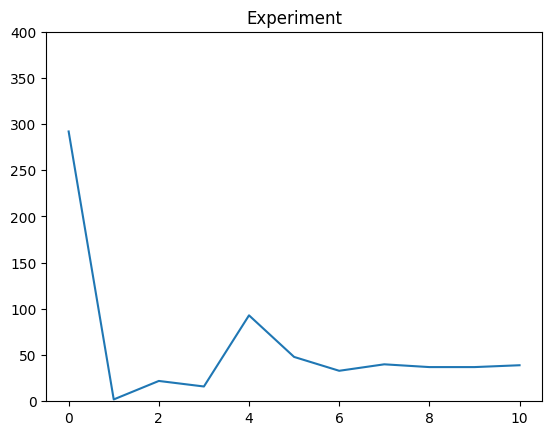

In [ ]:
display_losses(win_counts_exp, "Experiment")

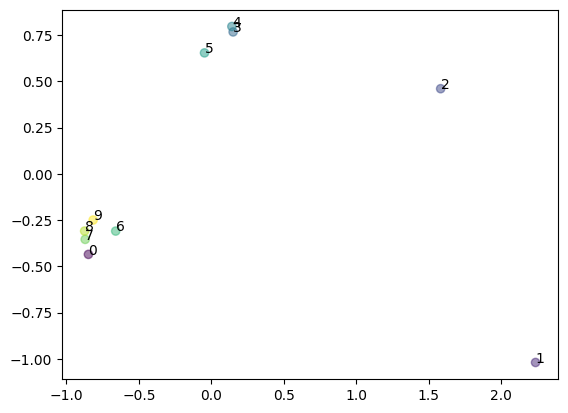

In [ ]:
# @title Plot shared critic embeddings
import numpy as np
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

vf_last = algo.learner_group._learner._module[SHARED_CRITIC_ID].vf[-1]
X = np.array(vf_last.weight.detach().clone())
Xb = np.array(vf_last.bias.detach().clone())

'''emb_c = X.shape[0]//2
Xmu = X[:emb_c, :]
Xsigma = X[emb_c:, :]
Xb_mu = np.expand_dims(Xb[:emb_c], 1)
Xb_sigma = np.expand_dims(Xb[emb_c:], 1)'''
Xgamma, Xlogv, Xlog_alpha_minus_one, Xlog_beta = np.array_split(X, 4, 0)
Xbgamma, Xblogv, Xblog_alpha_minus_one, Xblog_beta = [np.expand_dims(x, -1) for x in np.array_split(Xb, 4, 0)]
# Concatenate all parts of the "embeddings"
X = np.concatenate([Xgamma, Xlogv, Xlog_alpha_minus_one, Xlog_beta,
                    Xbgamma, Xblogv, Xblog_alpha_minus_one, Xblog_beta], axis=1)

# Filter out untrained embeddings
X = X[:10]

# PCA embeddings of each agent
pca = PCA(n_components=2)
proj = pca.fit_transform(X)

fig, ax = plt.subplots()
ax.scatter(proj[:,0],proj[:,1], alpha=0.5, c=range(X.shape[0]))

for i in range(0,X.shape[0],1):
  ax.annotate(i, (proj[i,0], proj[i,1]))

In [ ]:
# @title WR calculations
learned_agent = algo.env_runner.module['main']
agent_list = algo.config.policies

win_rates = calc_wrs(agent_list,N=400)

Calculating win rates for main_v1
Calculating win rates for main_v2
Calculating win rates for main_v3
Calculating win rates for main_v4
Calculating win rates for main_v5
Calculating win rates for main_v6
Calculating win rates for main_v7
Calculating win rates for main_v8
Calculating win rates for main_v9
Calculating win rates for main_v10


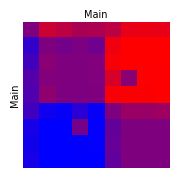

In [ ]:
# @title vis
merge = True # @param {"type":"boolean"}
show_draws = False # @param {"type":"boolean"}

main_agents = list(filter(lambda x: 'main_v' in x, agent_list))

groups = [
    ("Main", main_agents[:-1]),
]

generate_visualization(groups, win_rates, merge, show_draws)

### Without the priors & regularization loss

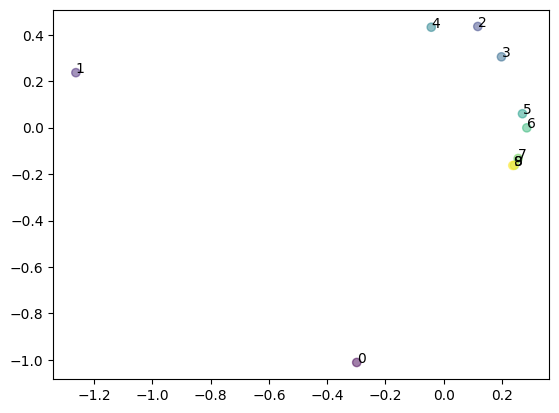

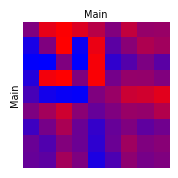